# 파일 불러오기

In [ ]:
# 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# # 그래프 한글 최적화
# !pip -q install matplotlib pandas numpy wordcloud networkx apyori
# !sudo apt-get install -y fonts-nanum
# !sudo fc-cache -fv
# !rm ~/.cache/matplotlib -rf

In [ ]:
# 경고 제거
import warnings
warnings.filterwarnings('ignore')

from IPython.display import display
import matplotlib.pyplot as plt

In [ ]:
# 전처리가 완료된 주식, 뉴스 데이터
import pandas as pd
stock_samsung=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/SAMSUNG/Stocks/2024_processing_samsung.csv',encoding="cp949")
stock_lg=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/LG_energysolution/Stocks/2024_processing_lg.csv',encoding="cp949")
stock_sk=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/SK_hynix/Stocks/2024_processing_sk.csv',encoding="cp949")

news_samsung=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/SAMSUNG/News/naver_finance_titles_삼성전자_2024-01-01_to_2024-12-31.csv',encoding="utf-8")
news_lg=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/LG_energysolution/News/naver_finance_titles_LG에너지솔루션_LG엔솔_2024.csv',encoding="utf-8")
news_sk=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/SK_hynix/News/naver_finance_titles_SK하이닉스_2024-01-01_to_2024-12-31.csv',encoding="utf-8")

In [ ]:
display(stock_samsung.info())
display(stock_lg.info())
display(stock_sk.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  244 non-null    int64  
 1   Date        244 non-null    object 
 2   종가          244 non-null    int64  
 3   차액          244 non-null    int64  
 4   등락률         244 non-null    float64
 5   거래량         244 non-null    int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 11.6+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  244 non-null    int64  
 1   Date        244 non-null    object 
 2   종가          244 non-null    int64  
 3   차액          244 non-null    int64  
 4   등락률         244 non-null    float64
 5   거래량         244 non-null    int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 11.6+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  244 non-null    int64  
 1   Date        244 non-null    object 
 2   종가          244 non-null    int64  
 3   차액          244 non-null    int64  
 4   등락률         244 non-null    float64
 5   거래량         244 non-null    int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 11.6+ KB


None

In [ ]:
display(news_samsung.info())
display(news_lg.info())
display(news_sk.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2110 entries, 0 to 2109
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    2110 non-null   object
 1   title   2110 non-null   object
dtypes: object(2)
memory usage: 33.1+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    225 non-null    object
 1   title   225 non-null    object
dtypes: object(2)
memory usage: 3.6+ KB


None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1040 entries, 0 to 1039
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    1040 non-null   object
 1   title   1040 non-null   object
dtypes: object(2)
memory usage: 16.4+ KB


None

# 삼성전자 시각화


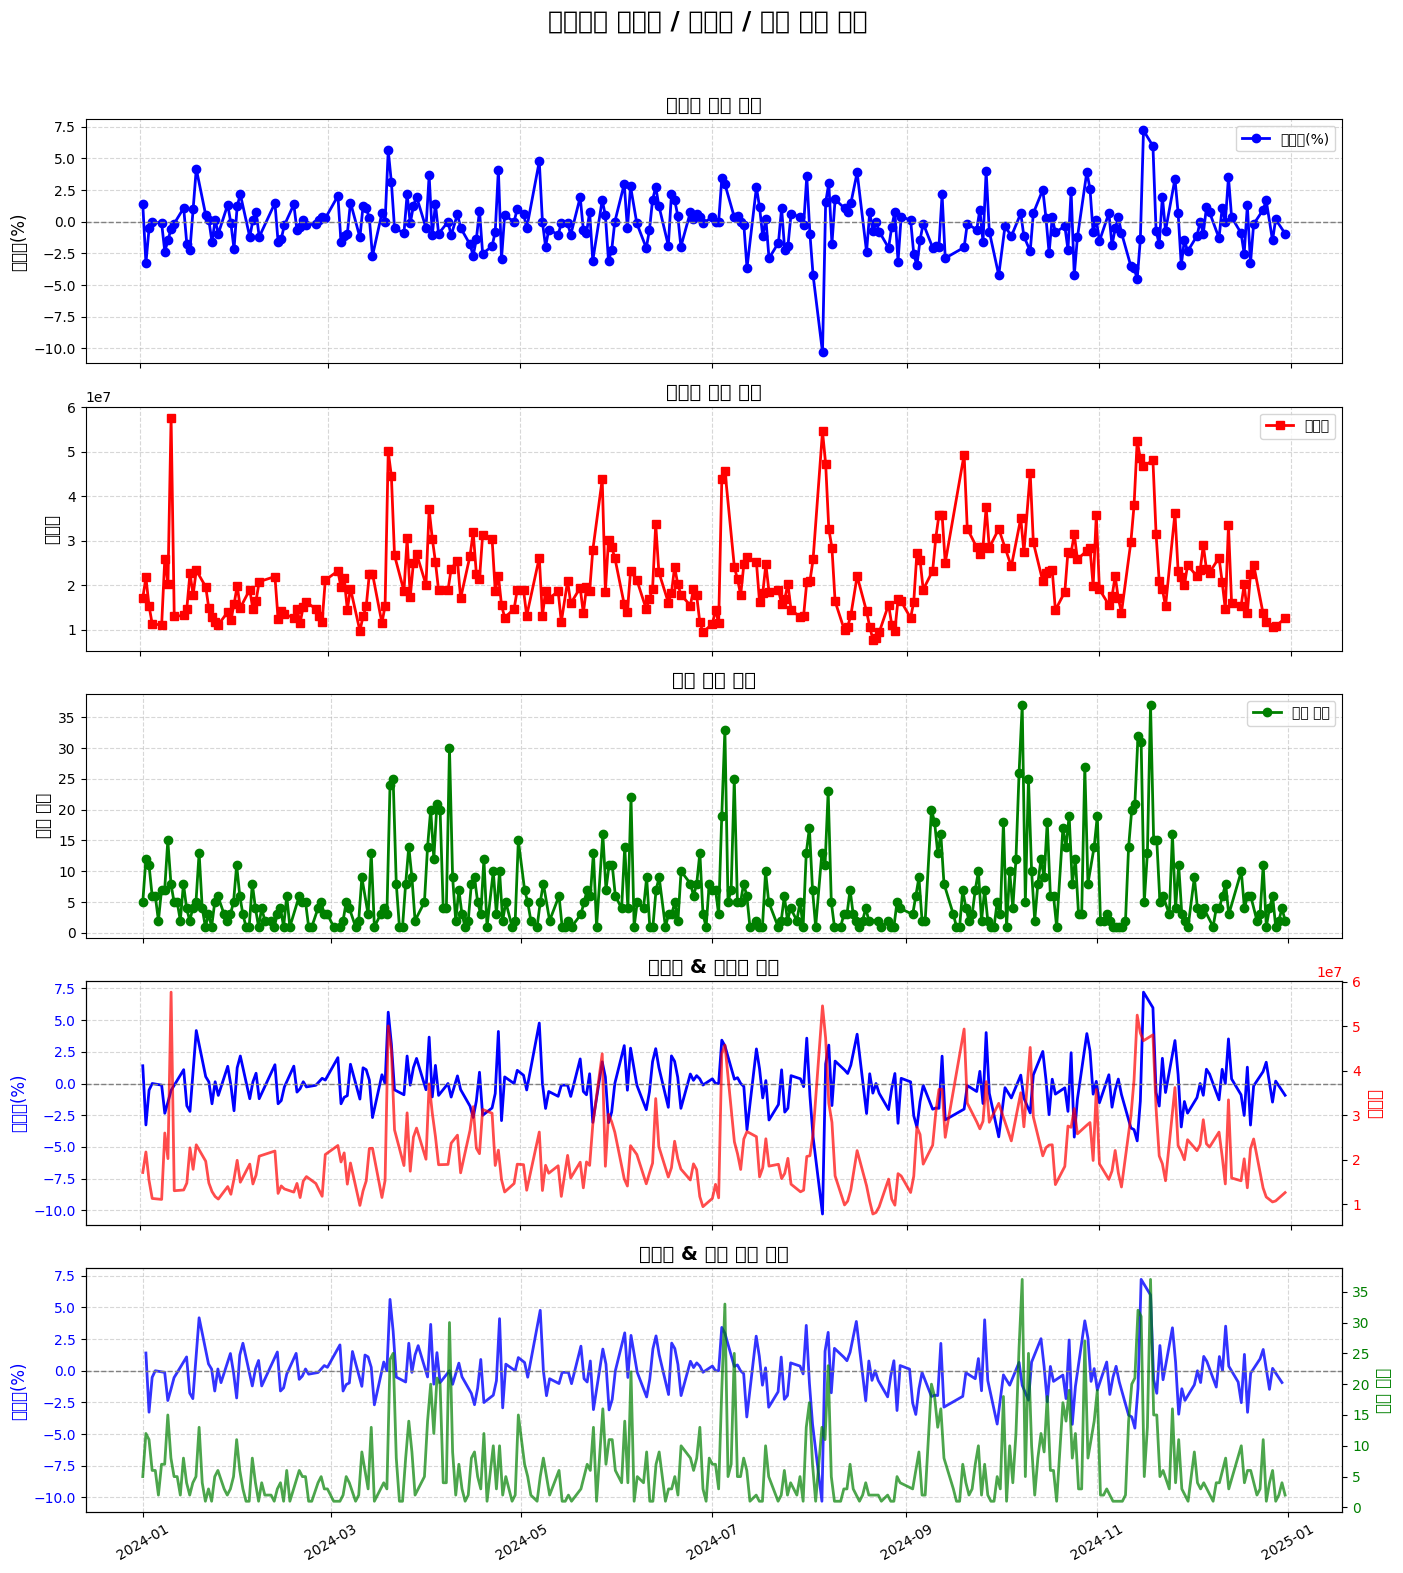

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


# 주식, 뉴스 데이터 준비
data = stock_samsung[['Date', '등락률', '거래량']].copy()
data["Date"] = pd.to_datetime(data["Date"])
news_samsung_1 = news_samsung.groupby('date').count()
news_samsung_2 = news_samsung_1.reset_index()
news_samsung_2["date"] = pd.to_datetime(news_samsung_2["date"])


# Figure 제작
fig, axes = plt.subplots(5, 1, figsize=(14, 16))
fig.suptitle("삼성전자 등락률 / 거래량 / 뉴스 개수 추이", fontsize=18, fontweight='bold')


# 등락률 추이
axes[0].plot(data["Date"], data["등락률"], marker='o', color='blue', linewidth=2, label='등락률(%)')
axes[0].axhline(y=0, color='gray', linestyle='--', linewidth=1)
axes[0].set_title("등락률 변화 추이", fontsize=14, fontweight='bold')
axes[0].set_ylabel("등락률(%)", fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()


# 거래량 추이
axes[1].plot(data["Date"], data["거래량"],marker='s', color='red', linewidth=2, label='거래량')
axes[1].set_title("거래량 변화 추이", fontsize=14, fontweight='bold')
axes[1].set_ylabel("거래량", fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()


# 뉴스 개수 추이
axes[2].plot(news_samsung_2["date"], news_samsung_2["title"], marker='o', color='green', linewidth=2, label='뉴스 개수')
axes[2].set_title("뉴스 개수 추이", fontsize=14, fontweight='bold')
axes[2].set_ylabel("뉴스 개수", fontsize=12)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend()


# 등락률 + 거래량 추이
ax1 = axes[3]
ax2 = ax1.twinx()

ax1.plot(data["Date"], data["등락률"],color='blue', label='등락률(%)', linewidth=2)
ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel("등락률(%)", color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')

ax2.plot(data["Date"], data["거래량"],color='red', label='거래량', linewidth=2, alpha=0.7)
ax2.set_ylabel("거래량", color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')

ax1.set_title("등락률 & 거래량 추이", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)


# 등락률 + 뉴스 개수 추이
ax1 = axes[4]
ax2 = ax1.twinx()

ax1.plot(data["Date"], data["등락률"], color='blue',linewidth=2, alpha=0.8, label='등락률(%)')
ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel("등락률(%)", color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')

ax2.plot(news_samsung_2["date"], news_samsung_2["title"], color='green',linewidth=2, alpha=0.7, label='뉴스 개수')
ax2.set_ylabel("뉴스 개수", color='green', fontsize=12)
ax2.tick_params(axis='y', labelcolor='green')

ax1.set_title("등락률 & 뉴스 개수 추이", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)


#정리
for ax in axes:
    ax.label_outer()
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

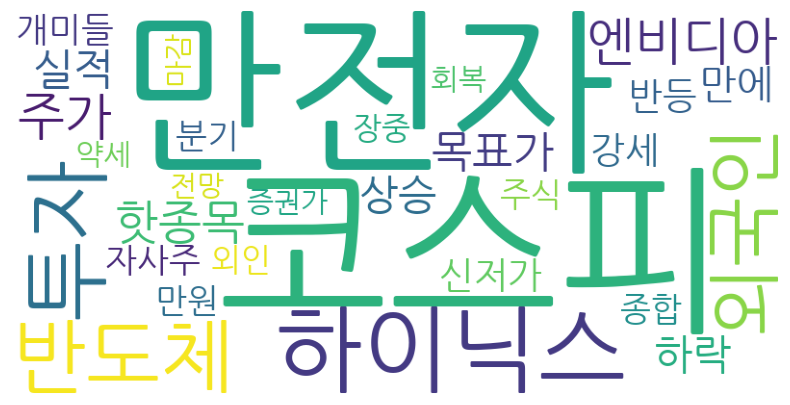

필터링한 데이터 개수: 123개


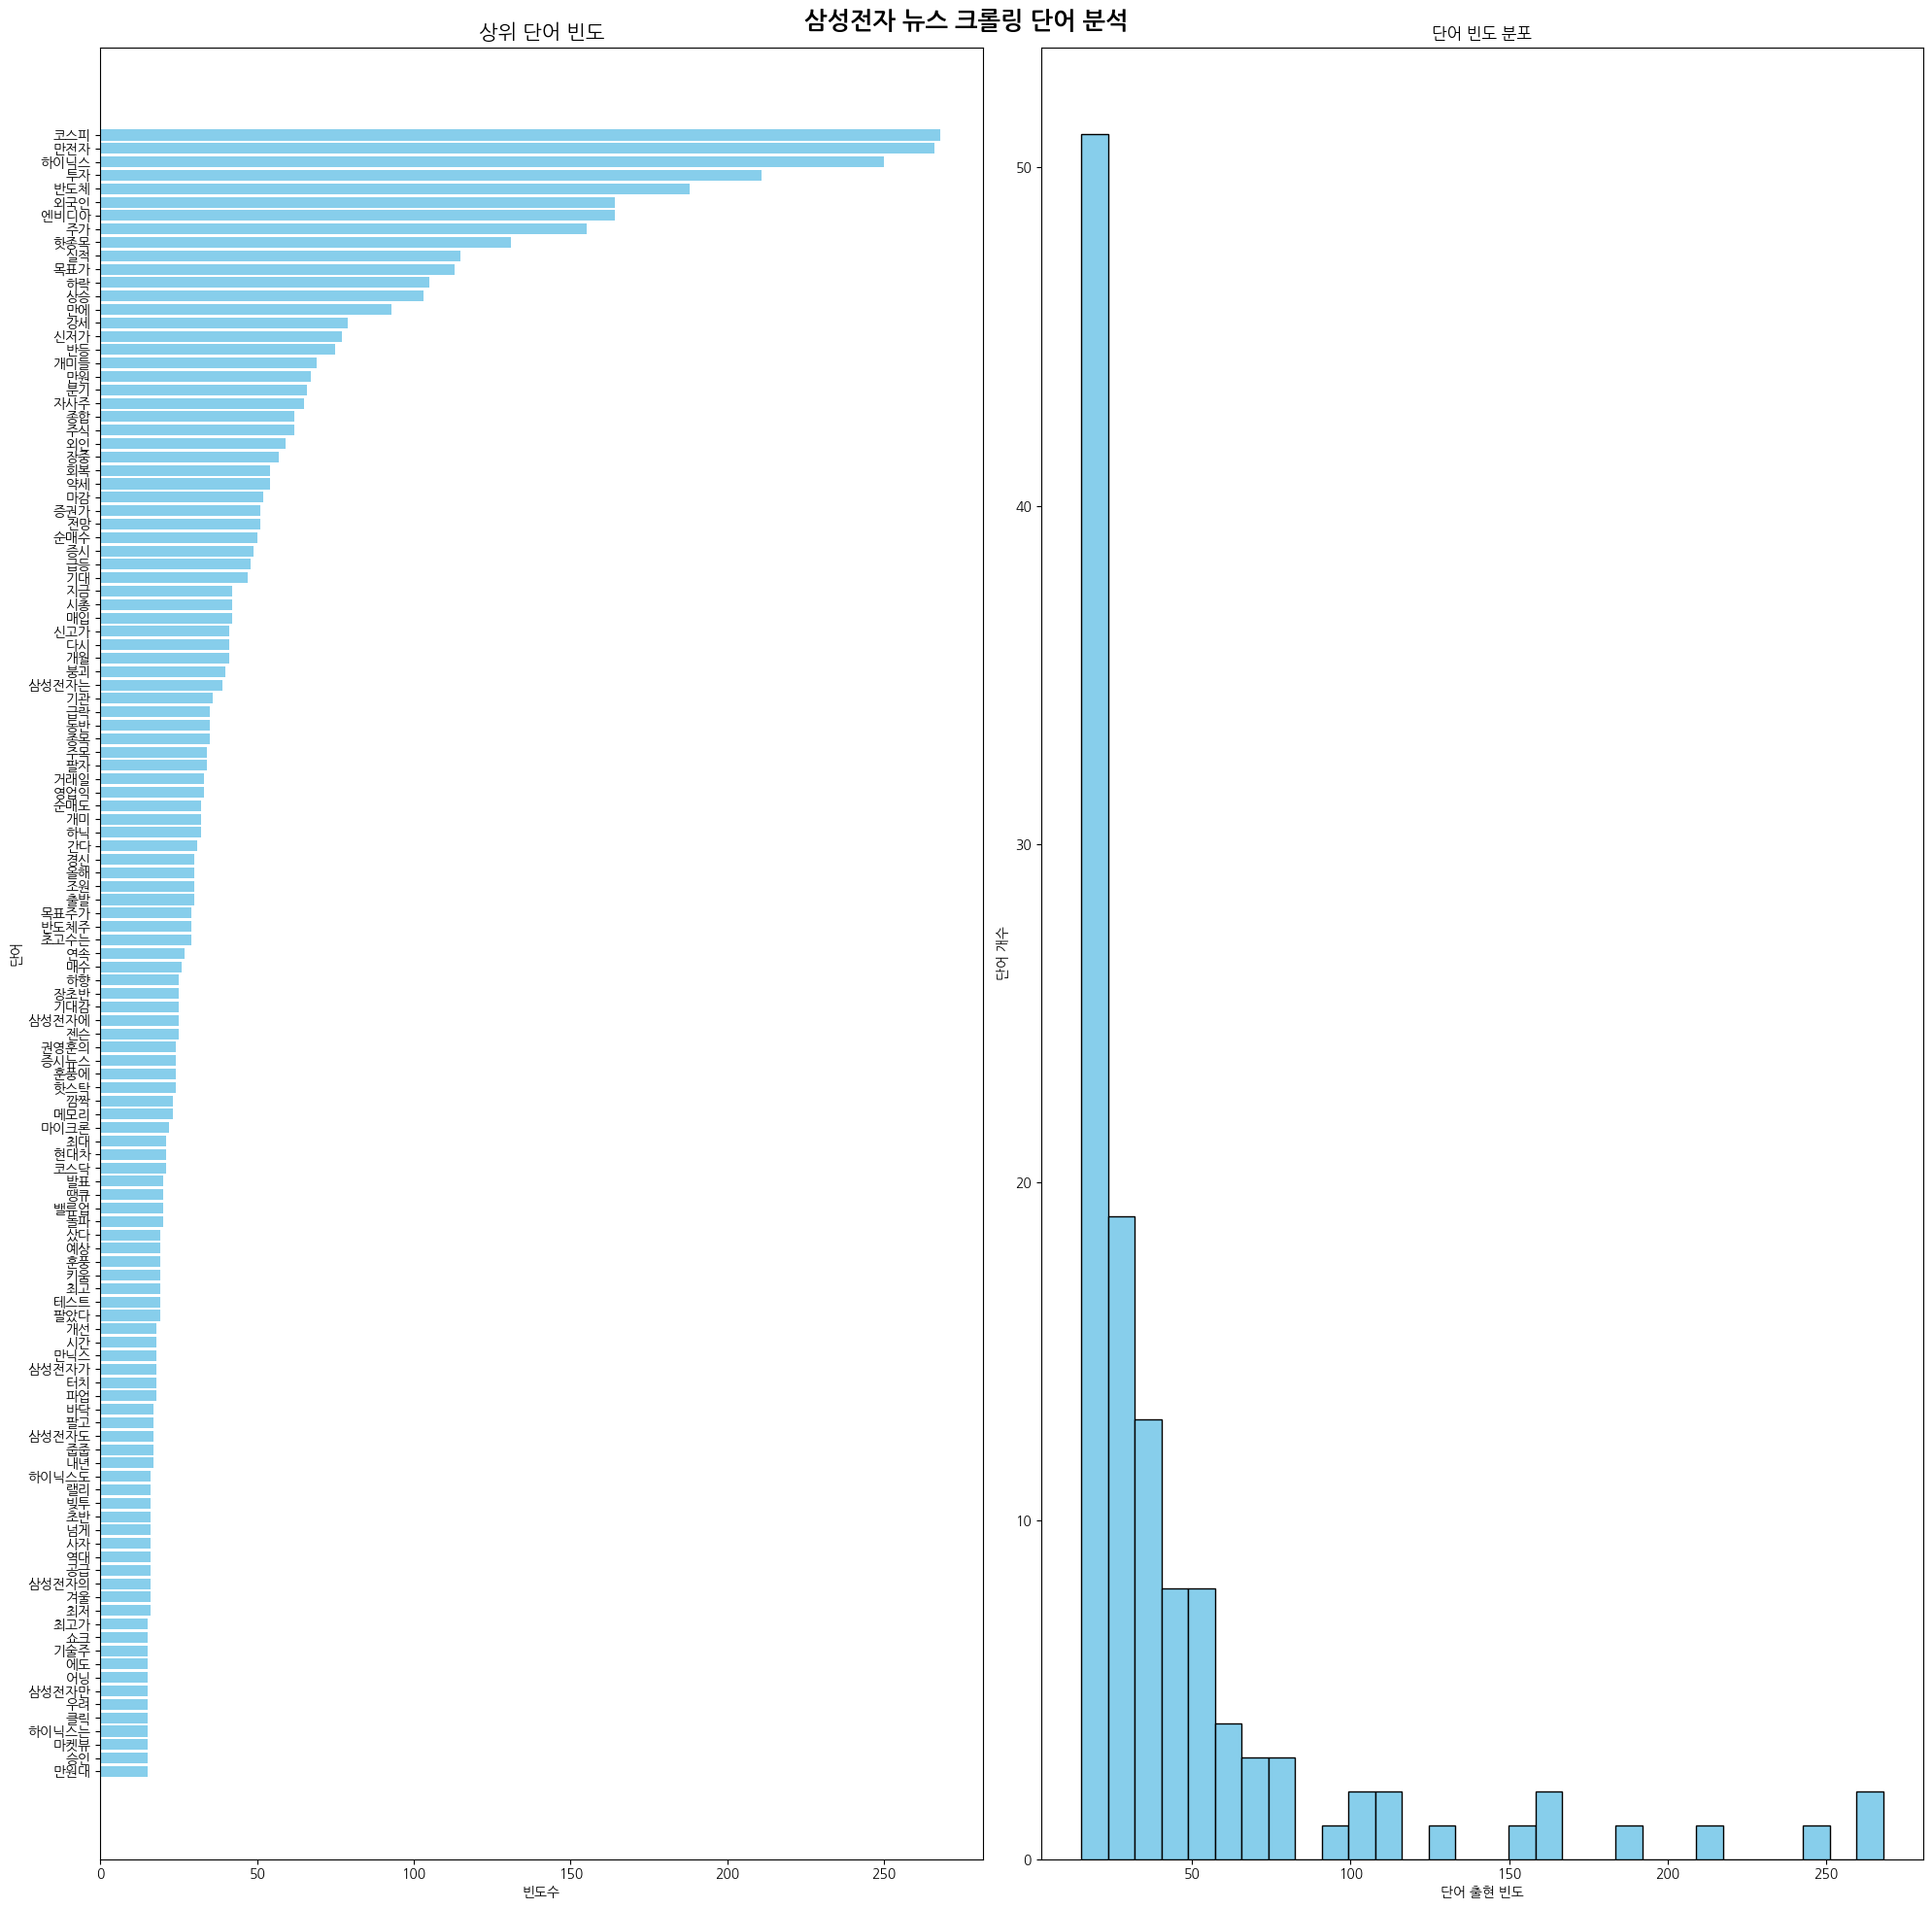

필터링한 키워드 전부 나열
코스피 268
만전자 266
하이닉스 250
투자 211
반도체 188
외국인 164
엔비디아 164
주가 155
핫종목 131
실적 115
목표가 113
하락 105
상승 103
만에 93
강세 79
신저가 77
반등 75
개미들 69
만원 67
분기 66
자사주 65
종합 62
주식 62
외인 59
장중 57
회복 54
약세 54
마감 52
증권가 51
전망 51
순매수 50
증시 49
급등 48
기대 47
지금 42
시총 42
매입 42
신고가 41
다시 41
개월 41
붕괴 40
삼성전자는 39
기관 36
급락 35
동반 35
종목 35
주목 34
팔자 34
거래일 33
영업익 33
순매도 32
개미 32
하닉 32
간다 31
경신 30
올해 30
조원 30
출발 30
목표주가 29
반도체주 29
초고수는 29
연속 27
매수 26
하향 25
장초반 25
기대감 25
삼성전자에 25
젠슨 25
권영훈의 24
증시뉴스 24
훈풍에 24
핫스탁 24
깜짝 23
메모리 23
마이크론 22
최대 21
현대차 21
코스닥 21
발표 20
땡큐 20
밸류업 20
돌파 20
샀다 19
예상 19
훈풍 19
키움 19
최고 19
테스트 19
팔았다 19
개선 18
시간 18
만닉스 18
삼성전자가 18
터치 18
파업 18
바닥 17
팔고 17
삼성전자도 17
줍줍 17
내년 17
하이닉스도 16
랠리 16
빚투 16
초반 16
넘게 16
사자 16
역대 16
공급 16
삼성전자의 16
겨울 16
최저 16
최고가 15
쇼크 15
기술주 15
에도 15
어닝 15
삼성전자만 15
우려 15
클릭 15
하이닉스는 15
마켓뷰 15
승인 15
만원대 15


In [ ]:
#워드클라우드

from wordcloud import WordCloud
from collections import Counter
import re, os, matplotlib.pyplot as plt

# 1) 텍스트 예시(자유 교체 가능). 파일을 쓰려면 with open(...).read()
text = "\n".join(news_samsung["title"].astype(str))

# 2) 아주 단순한 한국어 토큰화(한글만 남기고 공백 분리)
clean = re.sub(r"[^가-힣\s]", " ", text)
tokens = [w for w in clean.split() if len(w) > 1 and w not in '삼성전자']
freq = Counter(tokens)

# 3) 폰트 경로(설치했다면 나눔폰트 경로 사용)
FONT_PATH = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
font_path = FONT_PATH if os.path.exists(FONT_PATH) else None

wc = WordCloud(
    font_path=font_path,
    width=800, height=400, background_color="white",
    max_words=30
)
img = wc.generate_from_frequencies(freq)

plt.figure(figsize=(10,5))
plt.imshow(img); plt.axis("off"); plt.show()

plt.rc('font', family='NanumGothic')   # 한글 폰트 적용
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 깨짐 방지

import matplotlib.pyplot as plt

# 데이터 전처리
sorted_dict = dict(sorted(freq.items(), key=lambda x: x[1], reverse=True))
filtered_dict = {word: count for word, count in sorted_dict.items() if count >= 15} # 특정 키워드가 15번 이상 나온 것으로 설정
final_dict = dict(freq.most_common(len(filtered_dict)))
data = list(filtered_dict.values())

# 필터링한 데이터 수
print("===========================")
print(f"필터링한 데이터 개수: {len(filtered_dict)}개")
print("===========================")

# 데이터 준비
words = list(final_dict.keys())
counts = list(final_dict.values())

# Figure 1개에 2개 axes
fig, axes = plt.subplots(1, 2, figsize=(20,20))

# 선그래프
axes[0].barh(words, counts, color='skyblue')
axes[0].invert_yaxis()
axes[0].set_title("상위 단어 빈도", fontsize=15)
axes[0].set_xlabel("빈도수")
axes[0].set_ylabel("단어")

# Histogram — 분포 확인
axes[1].hist(data, bins=30, color='skyblue', edgecolor='black')
axes[1].set_title("단어 빈도 분포")
axes[1].set_xlabel("단어 출현 빈도")
axes[1].set_ylabel("단어 개수")

# 여백조절+제목표시
fig.suptitle("삼성전자 뉴스 크롤링 단어 분석", fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# 전부 나열
print("===========================")
print("필터링한 키워드 전부 나열")
print("===========================")
for word, count in filtered_dict.items():
    print(word, count)

# 키워드를 파일로 저장
df = pd.DataFrame(list(filtered_dict.items()), columns=['단어', '빈도'])
df.to_csv("/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/SAMSUNG/News/Word/samsung_word.csv", index=False, encoding="utf-8")

 # LG에너지솔루션 시각화

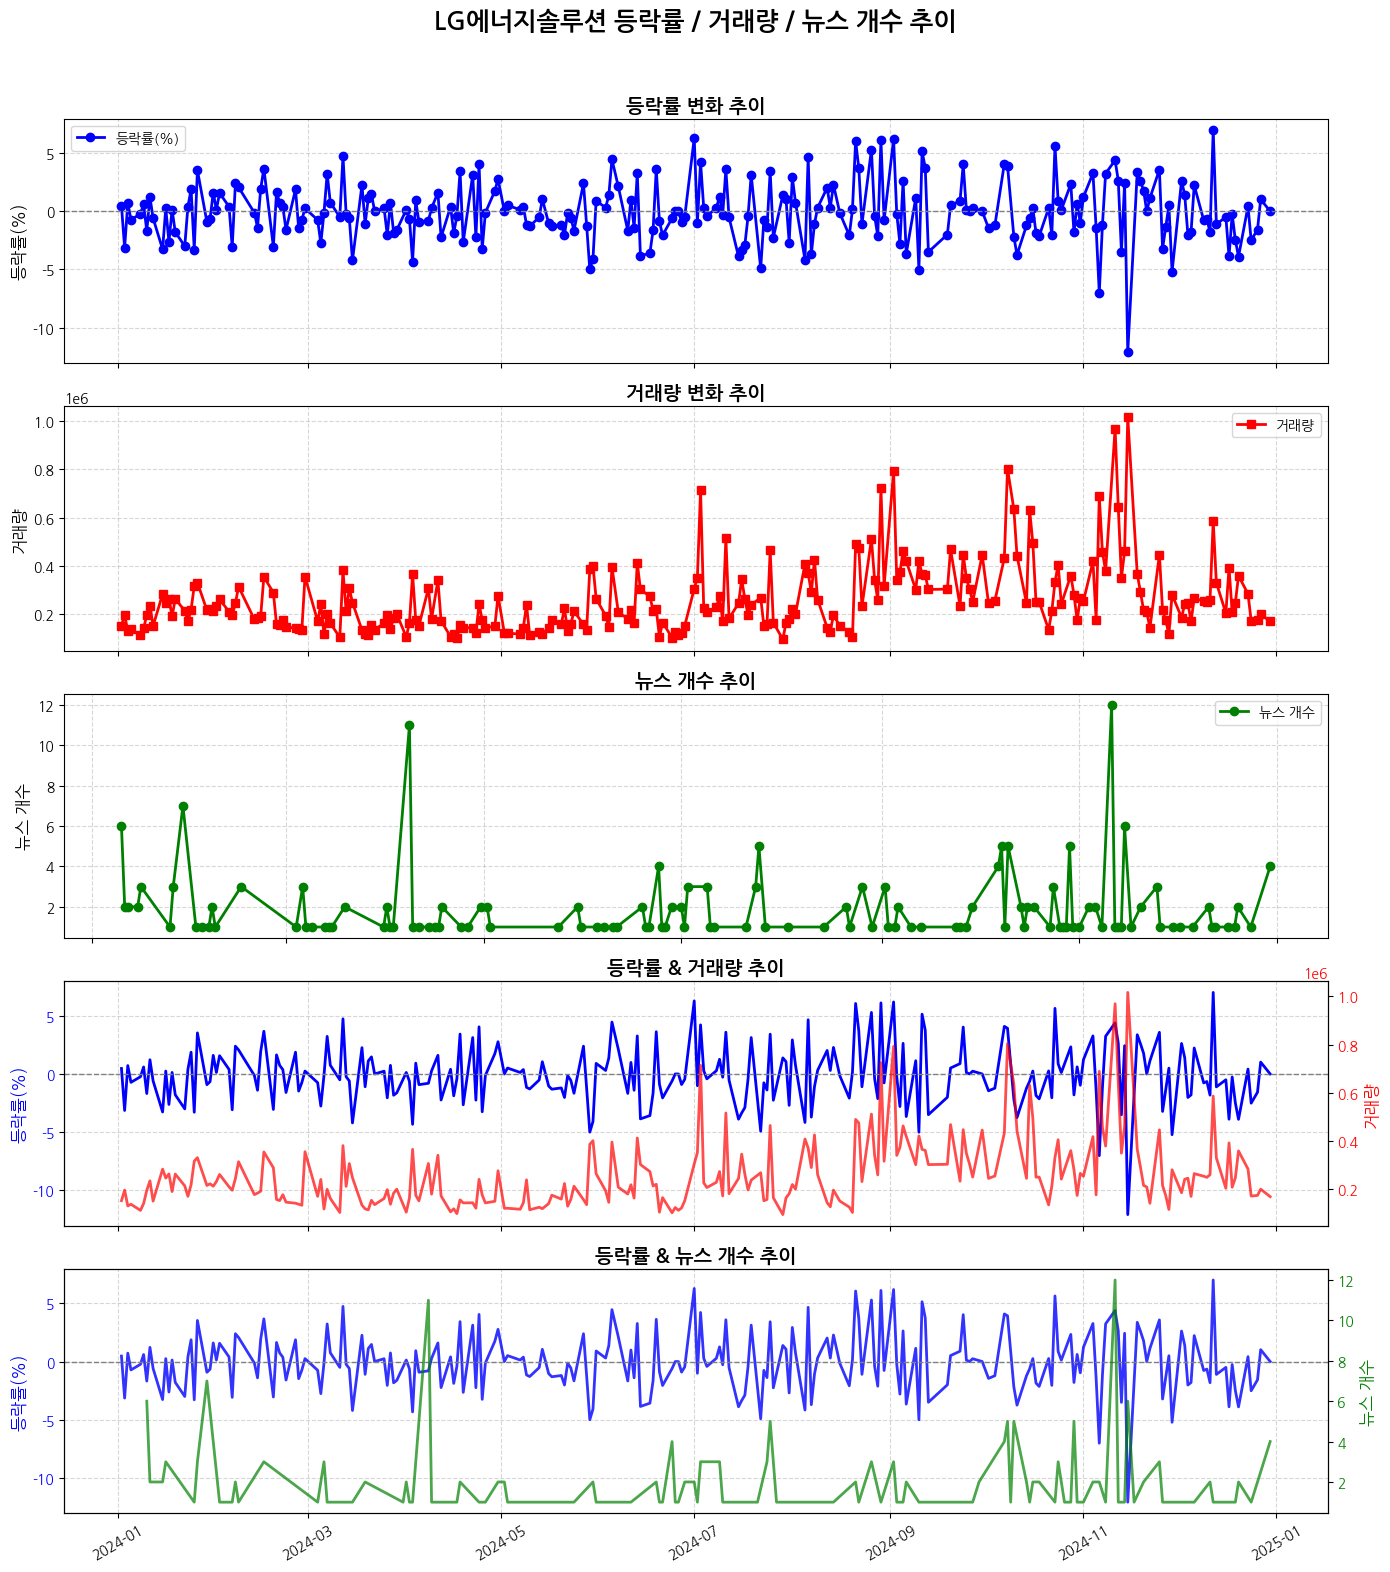

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


# 주식, 뉴스 데이터 준비
data = stock_lg[['Date', '등락률', '거래량']].copy()
data["Date"] = pd.to_datetime(data["Date"])
news_lg_1 = news_lg.groupby('date').count()
news_lg_2 = news_lg_1.reset_index()
news_lg_2["date"] = pd.to_datetime(news_lg_2["date"])


# Figure 제작
fig, axes = plt.subplots(5, 1, figsize=(14, 16))
fig.suptitle("LG에너지솔루션 등락률 / 거래량 / 뉴스 개수 추이", fontsize=18, fontweight='bold')


# 등락률 추이
axes[0].plot(data["Date"], data["등락률"], marker='o', color='blue', linewidth=2, label='등락률(%)')
axes[0].axhline(y=0, color='gray', linestyle='--', linewidth=1)
axes[0].set_title("등락률 변화 추이", fontsize=14, fontweight='bold')
axes[0].set_ylabel("등락률(%)", fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()


# 거래량 추이
axes[1].plot(data["Date"], data["거래량"],marker='s', color='red', linewidth=2, label='거래량')
axes[1].set_title("거래량 변화 추이", fontsize=14, fontweight='bold')
axes[1].set_ylabel("거래량", fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()


# 뉴스 개수 추이
axes[2].plot(news_lg_2["date"], news_lg_2["title"], marker='o', color='green', linewidth=2, label='뉴스 개수')
axes[2].set_title("뉴스 개수 추이", fontsize=14, fontweight='bold')
axes[2].set_ylabel("뉴스 개수", fontsize=12)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend()


# 등락률 + 거래량 추이
ax1 = axes[3]
ax2 = ax1.twinx()

ax1.plot(data["Date"], data["등락률"],color='blue', label='등락률(%)', linewidth=2)
ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel("등락률(%)", color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')

ax2.plot(data["Date"], data["거래량"],color='red', label='거래량', linewidth=2, alpha=0.7)
ax2.set_ylabel("거래량", color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')

ax1.set_title("등락률 & 거래량 추이", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)


# 등락률 + 뉴스 개수 추이
ax1 = axes[4]
ax2 = ax1.twinx()

ax1.plot(data["Date"], data["등락률"], color='blue',linewidth=2, alpha=0.8, label='등락률(%)')
ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel("등락률(%)", color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')

ax2.plot(news_lg_2["date"], news_lg_2["title"], color='green',linewidth=2, alpha=0.7, label='뉴스 개수')
ax2.set_ylabel("뉴스 개수", color='green', fontsize=12)
ax2.tick_params(axis='y', labelcolor='green')

ax1.set_title("등락률 & 뉴스 개수 추이", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)


#정리
for ax in axes:
    ax.label_outer()
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

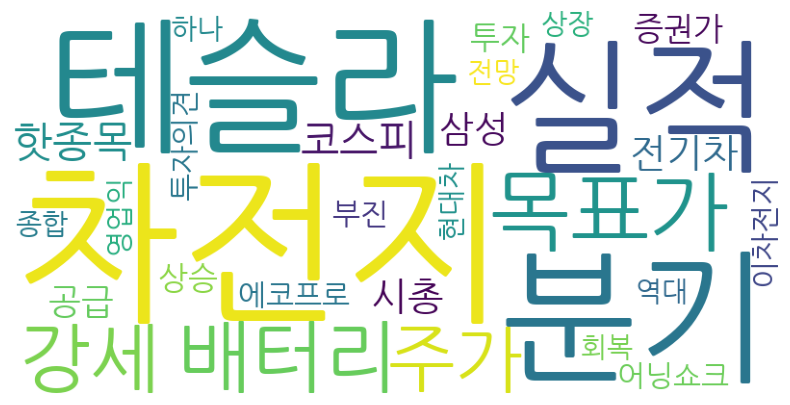

필터링한 데이터 개수: 106개


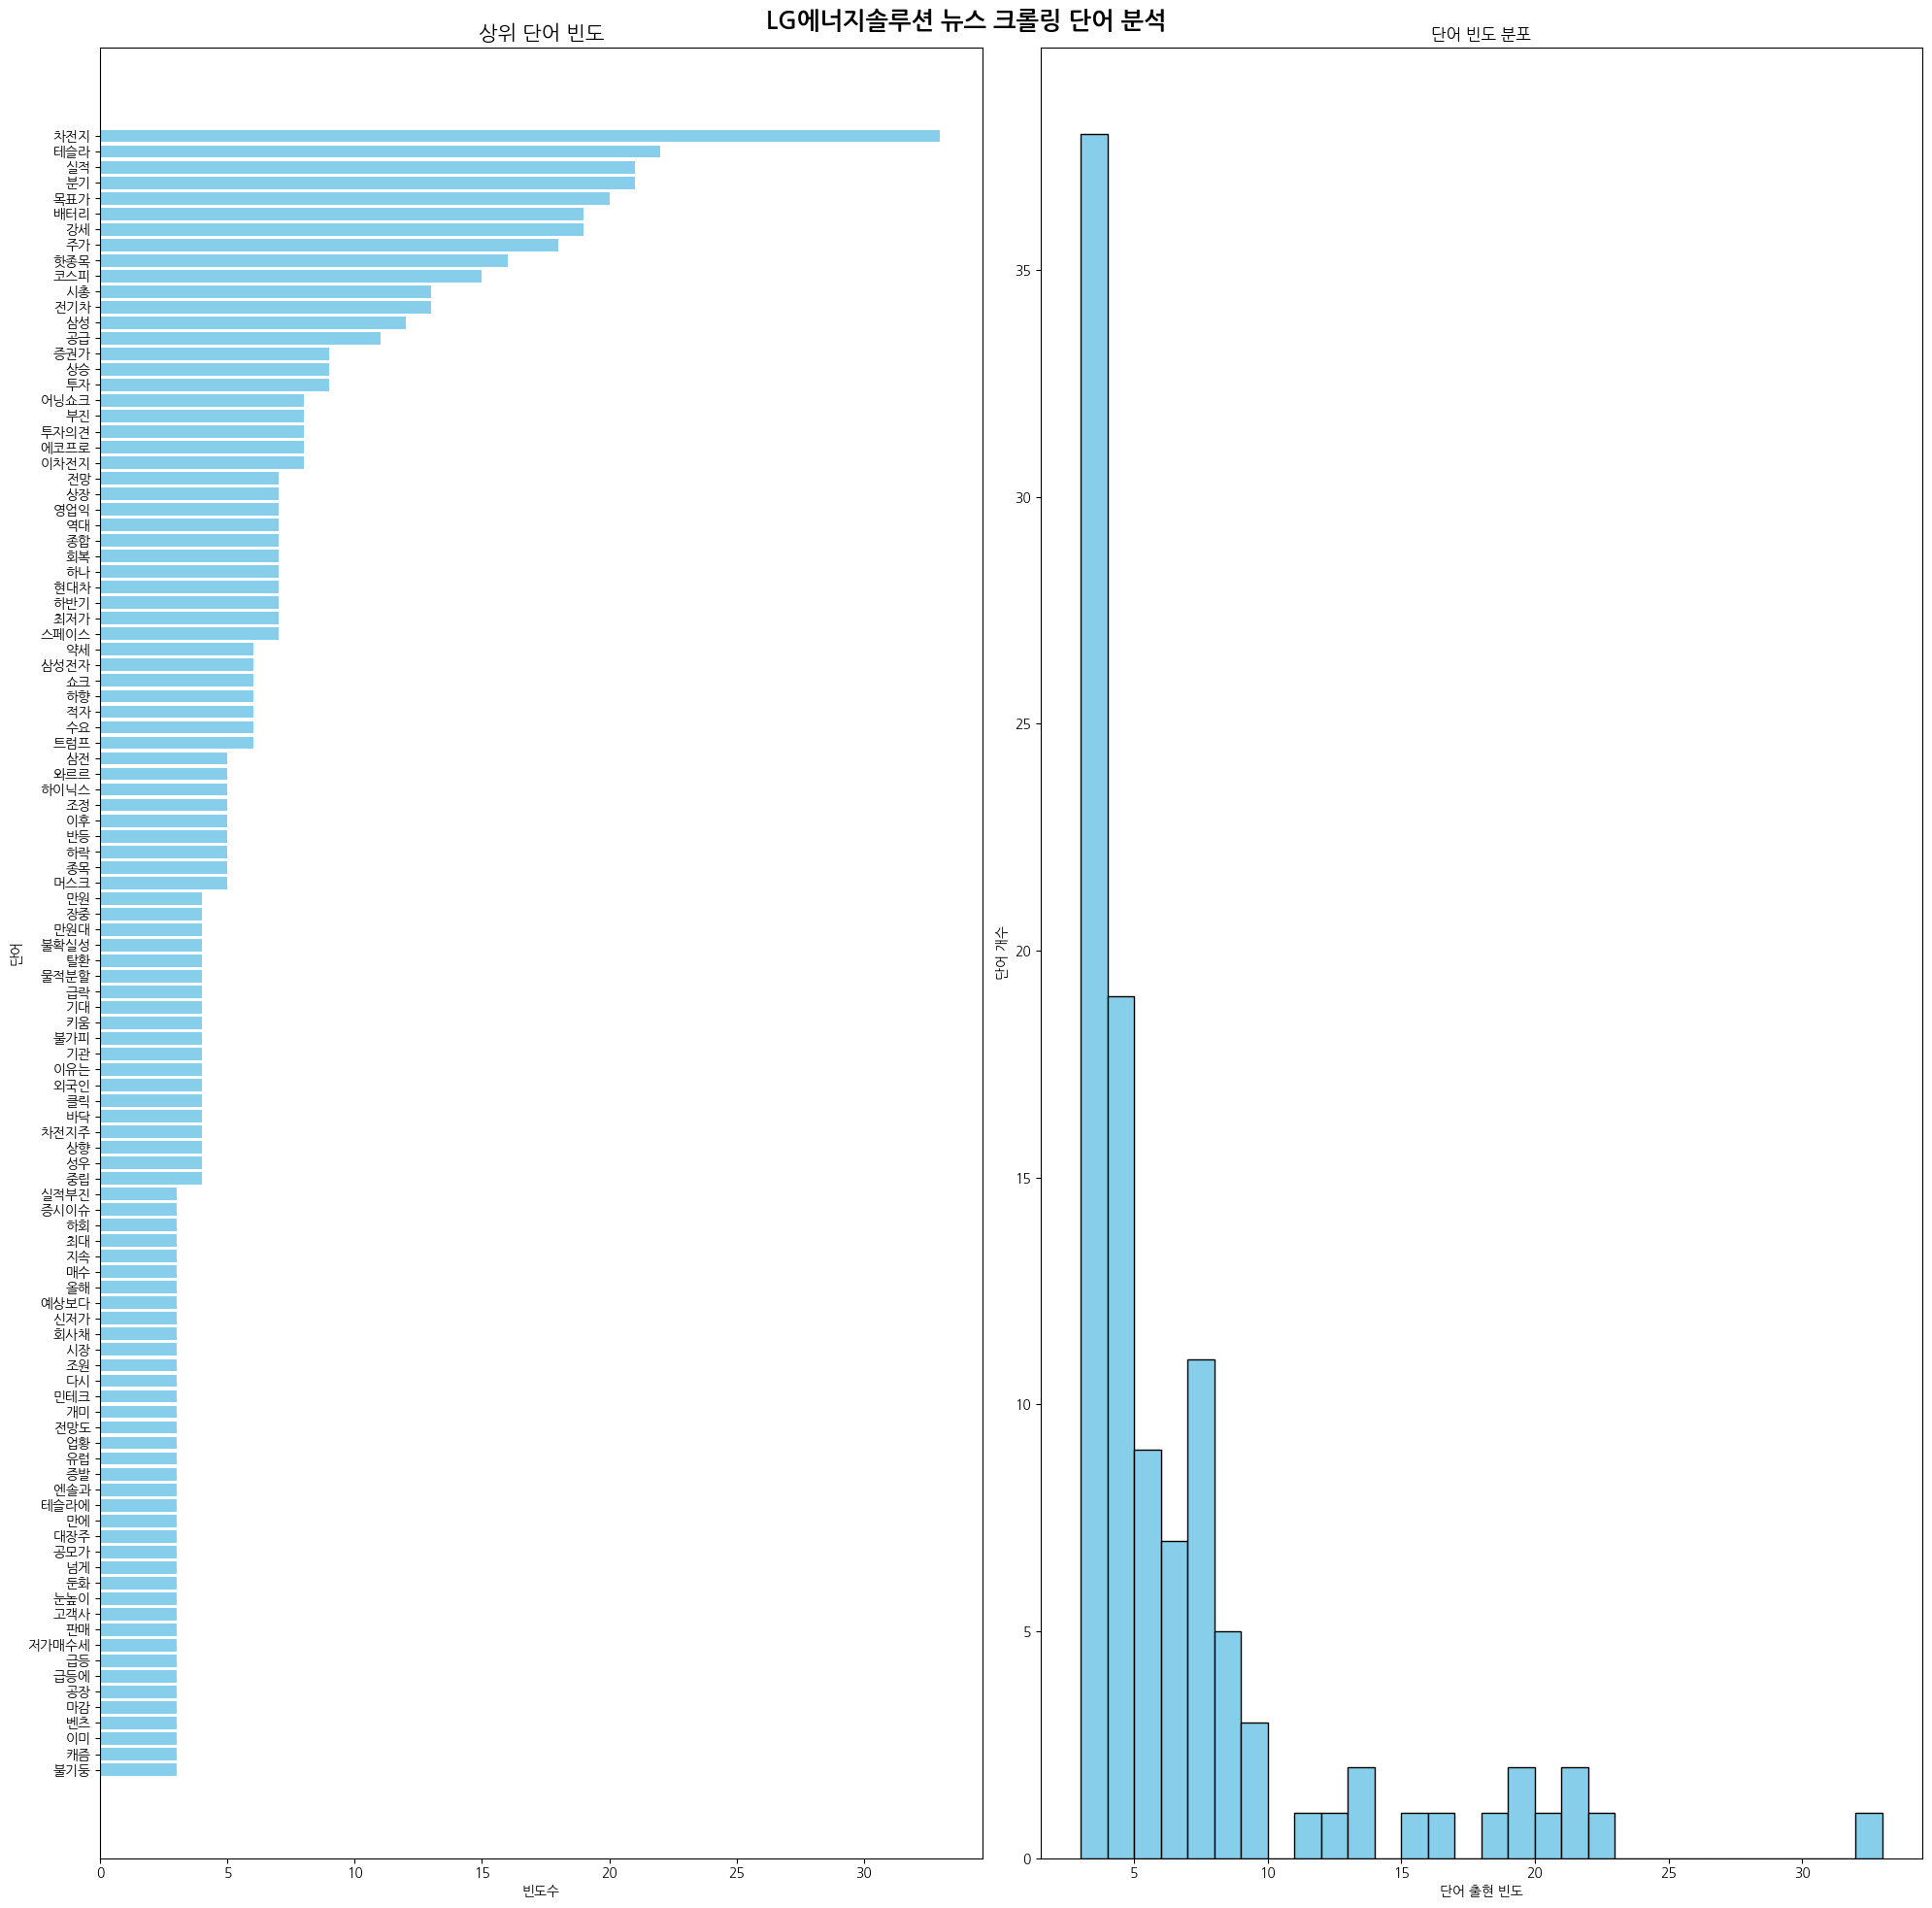

필터링한 키워드 전부 나열
차전지 33
테슬라 22
실적 21
분기 21
목표가 20
배터리 19
강세 19
주가 18
핫종목 16
코스피 15
시총 13
전기차 13
삼성 12
공급 11
증권가 9
상승 9
투자 9
어닝쇼크 8
부진 8
투자의견 8
에코프로 8
이차전지 8
전망 7
상장 7
영업익 7
역대 7
종합 7
회복 7
하나 7
현대차 7
하반기 7
최저가 7
스페이스 7
약세 6
삼성전자 6
쇼크 6
하향 6
적자 6
수요 6
트럼프 6
삼전 5
와르르 5
하이닉스 5
조정 5
이후 5
반등 5
하락 5
종목 5
머스크 5
만원 4
장중 4
만원대 4
불확실성 4
탈환 4
물적분할 4
급락 4
기대 4
키움 4
불가피 4
기관 4
이유는 4
외국인 4
클릭 4
바닥 4
차전지주 4
상향 4
성우 4
중립 4
실적부진 3
증시이슈 3
하회 3
최대 3
지속 3
매수 3
올해 3
예상보다 3
신저가 3
회사채 3
시장 3
조원 3
다시 3
민테크 3
개미 3
전망도 3
업황 3
유럽 3
증발 3
엔솔과 3
테슬라에 3
만에 3
대장주 3
공모가 3
넘게 3
둔화 3
눈높이 3
고객사 3
판매 3
저가매수세 3
급등 3
급등에 3
공장 3
마감 3
벤츠 3
이미 3
캐즘 3
불기둥 3


In [ ]:
#워드클라우드

from wordcloud import WordCloud
from collections import Counter
import re, os, matplotlib.pyplot as plt

# 1) 텍스트 예시(자유 교체 가능). 파일을 쓰려면 with open(...).read()
text = "\n".join(news_lg["title"].astype(str))

# 2) 아주 단순한 한국어 토큰화(한글만 남기고 공백 분리)
clean = re.sub(r"[^가-힣\s]", " ", text)
tokens = [w for w in clean.split() if len(w) > 1 and w not in ['엔솔', 'LG에너지솔루션','에너지솔루션']]
freq = Counter(tokens)

# 3) 폰트 경로(설치했다면 나눔폰트 경로 사용)
FONT_PATH = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
font_path = FONT_PATH if os.path.exists(FONT_PATH) else None

wc = WordCloud(
    font_path=font_path,
    width=800, height=400, background_color="white",
    max_words=30
)
img = wc.generate_from_frequencies(freq)

plt.figure(figsize=(10,5))
plt.imshow(img); plt.axis("off"); plt.show()

plt.rc('font', family='NanumGothic')   # 한글 폰트 적용
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 깨짐 방지

import matplotlib.pyplot as plt

# 데이터 전처리
sorted_dict = dict(sorted(freq.items(), key=lambda x: x[1], reverse=True))
filtered_dict = {word: count for word, count in sorted_dict.items() if count >= 3} # 특정 키워드가 3번 이상 나온 것으로 설정
final_dict = dict(freq.most_common(len(filtered_dict)))
data = list(filtered_dict.values())

# 필터링한 데이터 수
print("===========================")
print(f"필터링한 데이터 개수: {len(filtered_dict)}개")
print("===========================")

# 데이터 준비
words = list(final_dict.keys())
counts = list(final_dict.values())

# Figure 1개에 2개 axes
fig, axes = plt.subplots(1, 2, figsize=(20,20))

# 선그래프
axes[0].barh(words, counts, color='skyblue')
axes[0].invert_yaxis()
axes[0].set_title("상위 단어 빈도", fontsize=15)
axes[0].set_xlabel("빈도수")
axes[0].set_ylabel("단어")

# Histogram — 분포 확인
axes[1].hist(data, bins=30, color='skyblue', edgecolor='black')
axes[1].set_title("단어 빈도 분포")
axes[1].set_xlabel("단어 출현 빈도")
axes[1].set_ylabel("단어 개수")

# 여백조절+제목표시
fig.suptitle("LG에너지솔루션 뉴스 크롤링 단어 분석", fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# 전부 나열
print("===========================")
print("필터링한 키워드 전부 나열")
print("===========================")
for word, count in filtered_dict.items():
    print(word, count)

# 키워드를 파일로 저장
df = pd.DataFrame(list(filtered_dict.items()), columns=['단어', '빈도'])
df.to_csv("/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/LG_energysolution/News/Word/lg_word.csv", index=False, encoding="utf-8")

# SK하이닉스 시각화

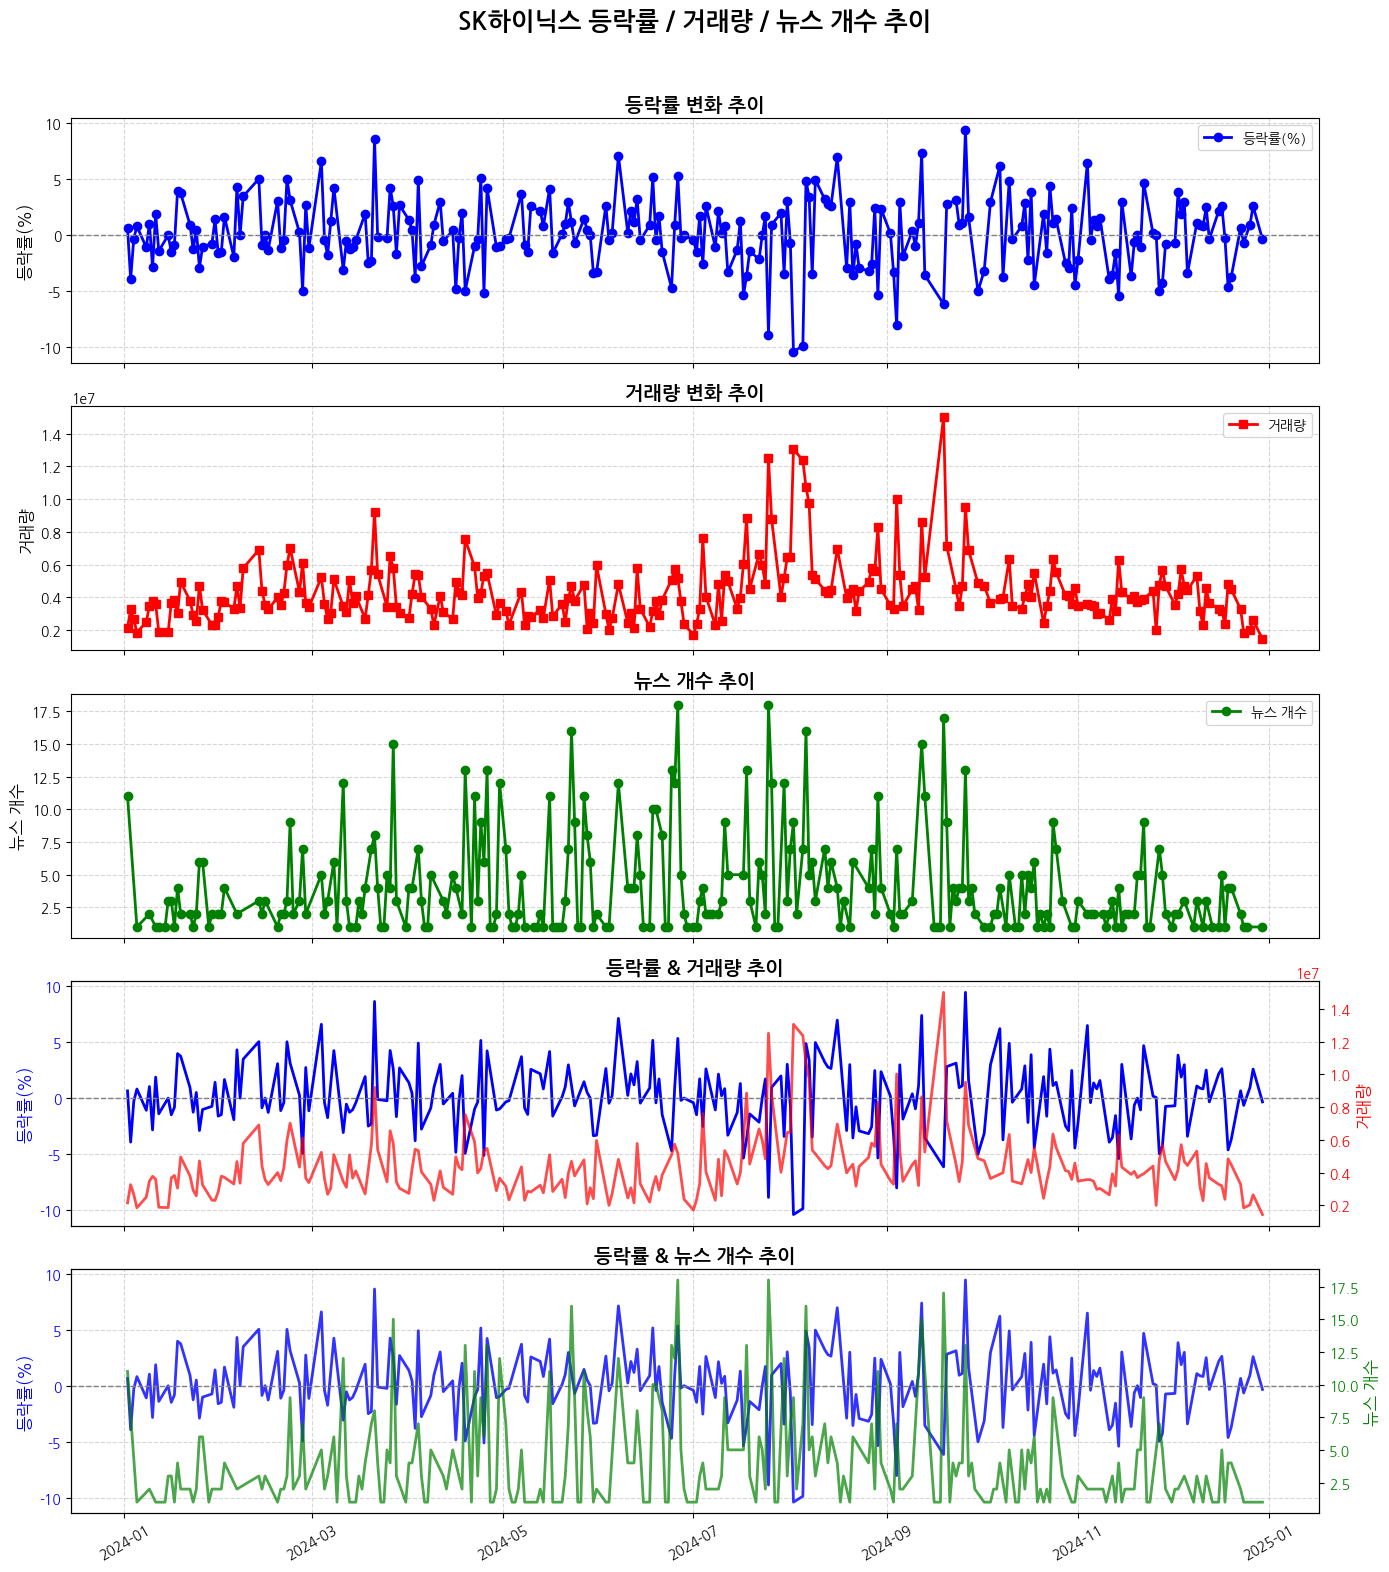

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


# 주식, 뉴스 데이터 준비
data = stock_sk[['Date', '등락률', '거래량']].copy()
data["Date"] = pd.to_datetime(data["Date"])
news_sk_1 = news_sk.groupby('date').count()
news_sk_2 = news_sk_1.reset_index()
news_sk_2["date"] = pd.to_datetime(news_sk_2["date"])


# Figure 제작
fig, axes = plt.subplots(5, 1, figsize=(14, 16))
fig.suptitle("SK하이닉스 등락률 / 거래량 / 뉴스 개수 추이", fontsize=18, fontweight='bold')


# 등락률 추이
axes[0].plot(data["Date"], data["등락률"], marker='o', color='blue', linewidth=2, label='등락률(%)')
axes[0].axhline(y=0, color='gray', linestyle='--', linewidth=1)
axes[0].set_title("등락률 변화 추이", fontsize=14, fontweight='bold')
axes[0].set_ylabel("등락률(%)", fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()


# 거래량 추이
axes[1].plot(data["Date"], data["거래량"],marker='s', color='red', linewidth=2, label='거래량')
axes[1].set_title("거래량 변화 추이", fontsize=14, fontweight='bold')
axes[1].set_ylabel("거래량", fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()


# 뉴스 개수 추이
axes[2].plot(news_sk_2["date"], news_sk_2["title"], marker='o', color='green', linewidth=2, label='뉴스 개수')
axes[2].set_title("뉴스 개수 추이", fontsize=14, fontweight='bold')
axes[2].set_ylabel("뉴스 개수", fontsize=12)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend()


# 등락률 + 거래량 추이
ax1 = axes[3]
ax2 = ax1.twinx()

ax1.plot(data["Date"], data["등락률"],color='blue', label='등락률(%)', linewidth=2)
ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel("등락률(%)", color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')

ax2.plot(data["Date"], data["거래량"],color='red', label='거래량', linewidth=2, alpha=0.7)
ax2.set_ylabel("거래량", color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')

ax1.set_title("등락률 & 거래량 추이", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)


# 등락률 + 뉴스 개수 추이
ax1 = axes[4]
ax2 = ax1.twinx()

ax1.plot(data["Date"], data["등락률"], color='blue',linewidth=2, alpha=0.8, label='등락률(%)')
ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel("등락률(%)", color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')

ax2.plot(news_sk_2["date"], news_sk_2["title"], color='green',linewidth=2, alpha=0.7, label='뉴스 개수')
ax2.set_ylabel("뉴스 개수", color='green', fontsize=12)
ax2.tick_params(axis='y', labelcolor='green')

ax1.set_title("등락률 & 뉴스 개수 추이", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)


#정리
for ax in axes:
    ax.label_outer()
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

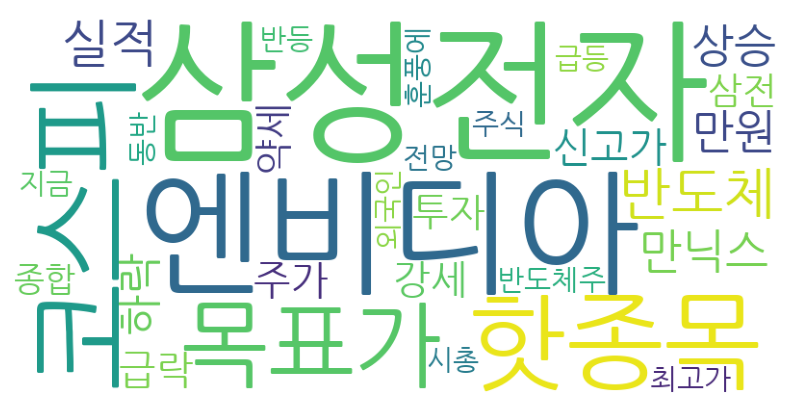

필터링한 데이터 개수: 121개


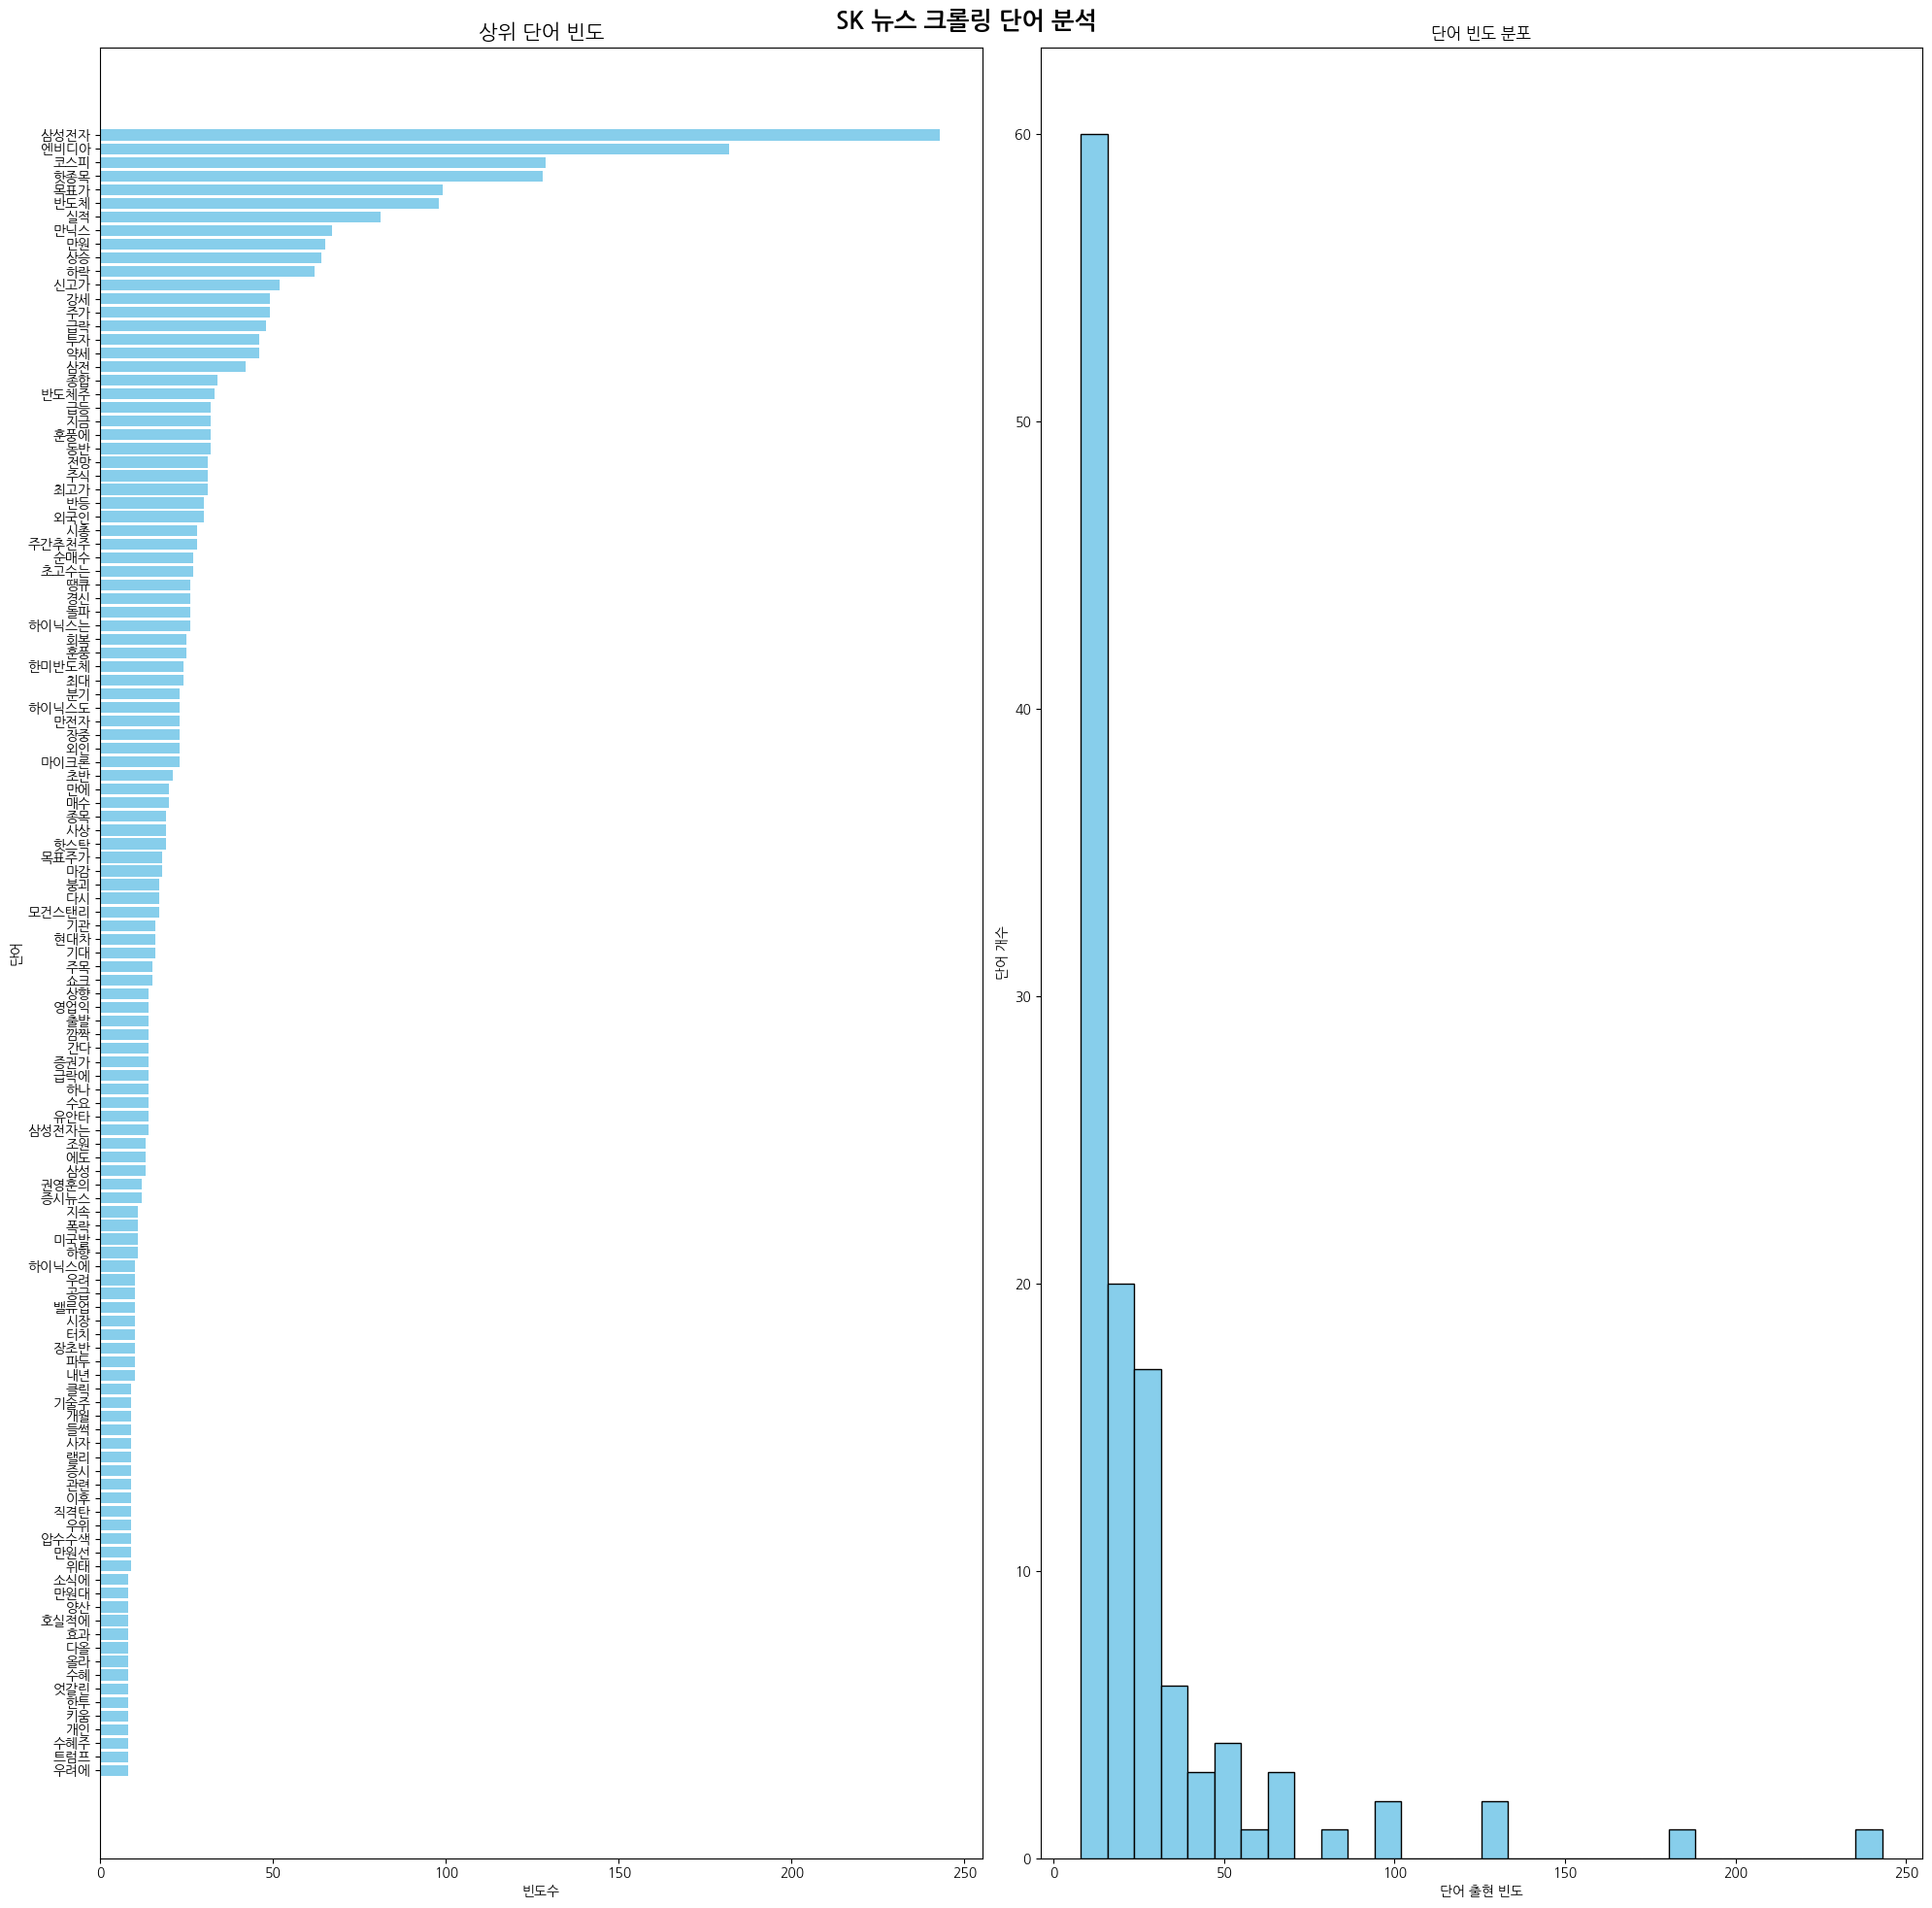

필터링한 키워드 전부 나열
삼성전자 243
엔비디아 182
코스피 129
핫종목 128
목표가 99
반도체 98
실적 81
만닉스 67
만원 65
상승 64
하락 62
신고가 52
강세 49
주가 49
급락 48
투자 46
약세 46
삼전 42
종합 34
반도체주 33
급등 32
지금 32
훈풍에 32
동반 32
전망 31
주식 31
최고가 31
반등 30
외국인 30
시총 28
주간추천주 28
순매수 27
초고수는 27
땡큐 26
경신 26
돌파 26
하이닉스는 26
회복 25
훈풍 25
한미반도체 24
최대 24
분기 23
하이닉스도 23
만전자 23
장중 23
외인 23
마이크론 23
초반 21
만에 20
매수 20
종목 19
사상 19
핫스탁 19
목표주가 18
마감 18
붕괴 17
다시 17
모건스탠리 17
기관 16
현대차 16
기대 16
주목 15
쇼크 15
상향 14
영업익 14
출발 14
깜짝 14
간다 14
증권가 14
급락에 14
하나 14
수요 14
유안타 14
삼성전자는 14
조원 13
에도 13
삼성 13
권영훈의 12
증시뉴스 12
지속 11
폭락 11
미국발 11
하향 11
하이닉스에 10
우려 10
공급 10
밸류업 10
시장 10
터치 10
장초반 10
파두 10
내년 10
클릭 9
기술주 9
개월 9
들썩 9
사자 9
랠리 9
증시 9
관련 9
이후 9
직격탄 9
우위 9
압수수색 9
만원선 9
위태 9
소식에 8
만원대 8
양산 8
호실적에 8
효과 8
다올 8
올라 8
수혜 8
엇갈린 8
한투 8
키움 8
개인 8
수혜주 8
트럼프 8
우려에 8


In [ ]:
#워드클라우드

from wordcloud import WordCloud
from collections import Counter
import re, os, matplotlib.pyplot as plt

# 1) 텍스트 예시(자유 교체 가능). 파일을 쓰려면 with open(...).read()
text = "\n".join(news_sk["title"].astype(str))

# 2) 아주 단순한 한국어 토큰화(한글만 남기고 공백 분리)
clean = re.sub(r"[^가-힣\s]", " ", text)
tokens = [w for w in clean.split() if len(w) > 1 and w not in ['하이닉스']]
freq = Counter(tokens)

# 3) 폰트 경로(설치했다면 나눔폰트 경로 사용)
FONT_PATH = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
font_path = FONT_PATH if os.path.exists(FONT_PATH) else None

wc = WordCloud(
    font_path=font_path,
    width=800, height=400, background_color="white",
    max_words=30
)
img = wc.generate_from_frequencies(freq)

plt.figure(figsize=(10,5))
plt.imshow(img); plt.axis("off"); plt.show()

plt.rc('font', family='NanumGothic')   # 한글 폰트 적용
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 깨짐 방지

import matplotlib.pyplot as plt

# 데이터 전처리
sorted_dict = dict(sorted(freq.items(), key=lambda x: x[1], reverse=True))
filtered_dict = {word: count for word, count in sorted_dict.items() if count >= 8} # 특정 키워드가 8번 이상 나온 것으로 설정
final_dict = dict(freq.most_common(len(filtered_dict)))
data = list(filtered_dict.values())

# 필터링한 데이터 수
print("===========================")
print(f"필터링한 데이터 개수: {len(filtered_dict)}개")
print("===========================")

# 데이터 준비
words = list(final_dict.keys())
counts = list(final_dict.values())

# Figure 1개에 2개 axes
fig, axes = plt.subplots(1, 2, figsize=(20,20))

# 선그래프
axes[0].barh(words, counts, color='skyblue')
axes[0].invert_yaxis()
axes[0].set_title("상위 단어 빈도", fontsize=15)
axes[0].set_xlabel("빈도수")
axes[0].set_ylabel("단어")

# Histogram — 분포 확인
axes[1].hist(data, bins=30, color='skyblue', edgecolor='black')
axes[1].set_title("단어 빈도 분포")
axes[1].set_xlabel("단어 출현 빈도")
axes[1].set_ylabel("단어 개수")

# 여백조절+제목표시
fig.suptitle("SK 뉴스 크롤링 단어 분석", fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# 전부 나열
print("===========================")
print("필터링한 키워드 전부 나열")
print("===========================")
for word, count in filtered_dict.items():
    print(word, count)

# 키워드를 파일로 저장
df = pd.DataFrame(list(filtered_dict.items()), columns=['단어', '빈도'])
df.to_csv("/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/SK_hynix/News/Words/sk_word.csv", index=False, encoding="utf-8")

# 긍/부정 단어를 활용한 뉴스 제목 긍/부정 평가

In [ ]:
# 파일 불러오기
words_samsung=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/SAMSUNG/News/Word/samsung_word_processing.csv',encoding="cp949")
words_lg=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/LG_energysolution/News/Word/lg_word_processing.csv',encoding="cp949")
words_sk=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/2025-2/[25.9~25.12] Bamboo DnA/DnA_project (Stock_and_News)/Data/SK_hynix/News/Words/sk_word_processing.csv',encoding="cp949")

In [ ]:
#뉴스 제목의 긍/부정 점수를 계산
def calculate_sentiment_score(news_df, keywords_df):
    keywords = keywords_df[['단어', '긍/부정']]

    def score_title(title):
        score = 0
        count = 0
        for _, row in keywords.iterrows():
            word = str(row["단어"])
            value = row["긍/부정"]
            if word in str(title):
                score += value
                count += 1
        if count == 0:
            return None
        return score / count

    news_df_scored = news_df.copy()
    news_df_scored["긍/부정점수"] = news_df_scored["title"].apply(score_title)
    news_df_scored["date"] = pd.to_datetime(news_df_scored["date"])
    daily_sentiment = news_df_scored.groupby("date")["긍/부정점수"].mean().reset_index()

    return daily_sentiment

daily_sentiment_samsung = calculate_sentiment_score(news_samsung, words_samsung)
daily_sentiment_lg = calculate_sentiment_score(news_lg, words_lg)
daily_sentiment_sk = calculate_sentiment_score(news_sk, words_sk)

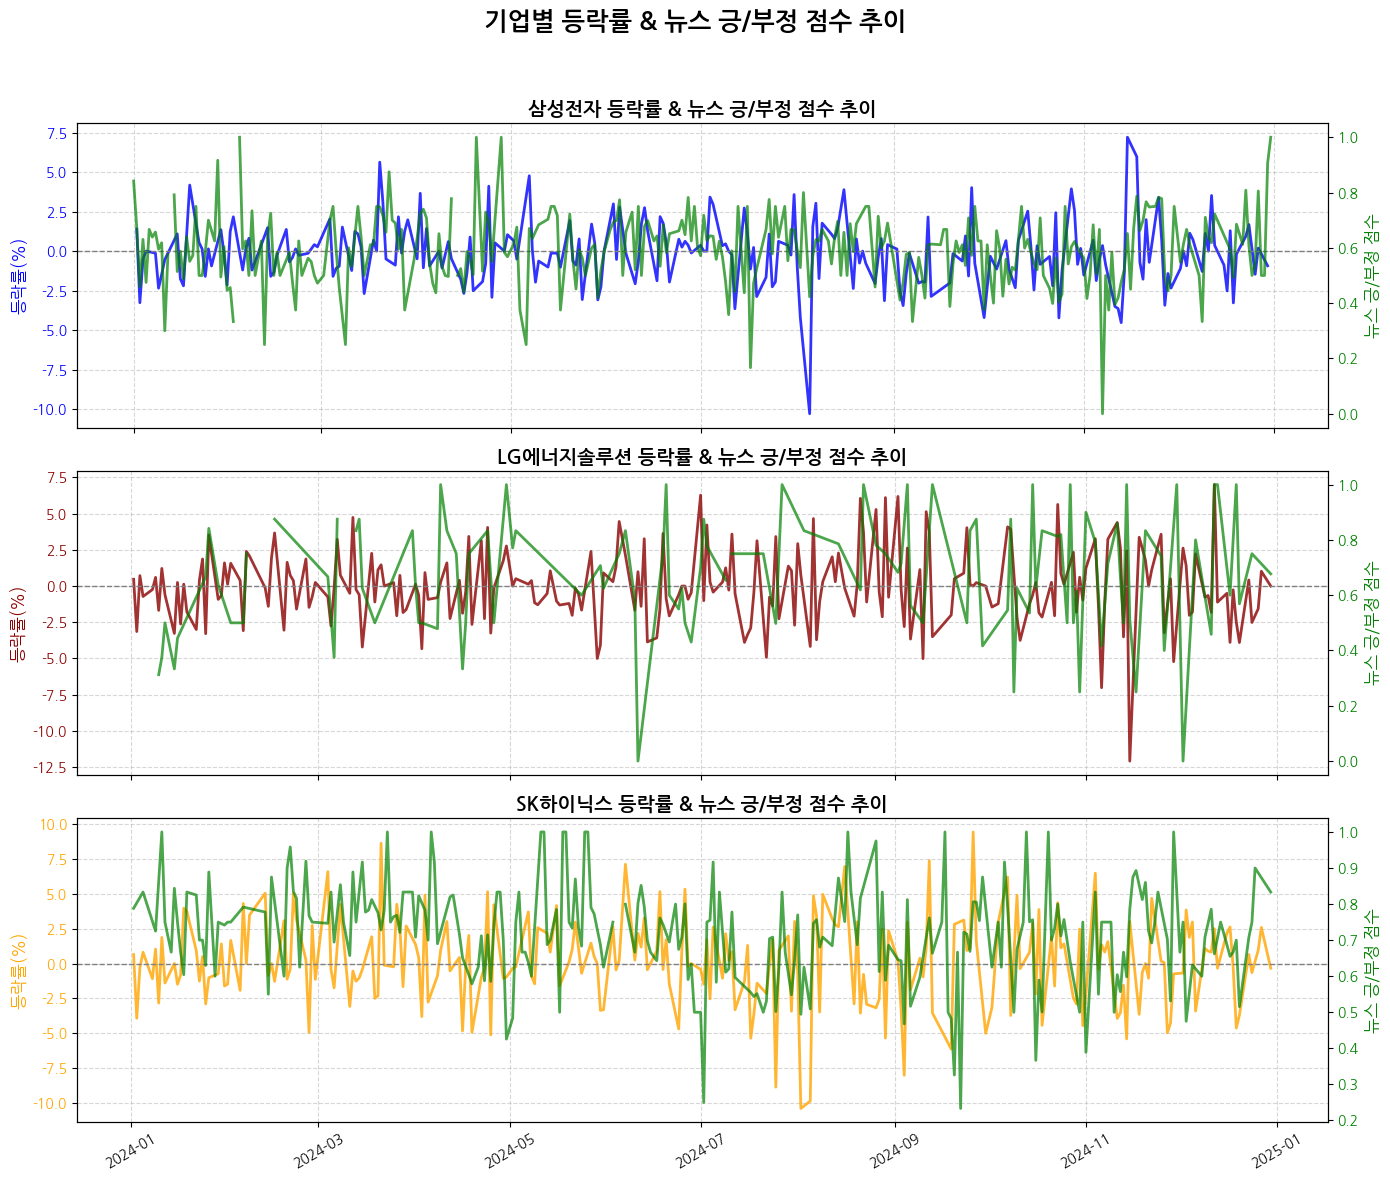

In [ ]:
# 날짜별 주식 등락률& 뉴스 긍/부정 점수 시각화
import matplotlib.pyplot as plt
import pandas as pd

# 각 데이터(Date 형 변환)
stock_samsung["Date"] = pd.to_datetime(stock_samsung["Date"])
stock_lg["Date"] = pd.to_datetime(stock_lg["Date"])
stock_sk["Date"] = pd.to_datetime(stock_sk["Date"])
daily_sentiment_samsung["date"] = pd.to_datetime(daily_sentiment_samsung["date"])
daily_sentiment_lg["date"] = pd.to_datetime(daily_sentiment_lg["date"])
daily_sentiment_sk["date"] = pd.to_datetime(daily_sentiment_sk["date"])

# Figure (3행 1열 subplot)
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
fig.suptitle("기업별 등락률 & 뉴스 긍/부정 점수 추이", fontsize=18, fontweight='bold')

# 1️. 삼성전자
ax1 = axes[0]
ax2 = ax1.twinx()
ax1.plot(stock_samsung["Date"], stock_samsung["등락률"], color='blue', linewidth=2, alpha=0.8, label='등락률(%)')
ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel("등락률(%)", color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')
ax2.plot(daily_sentiment_samsung["date"], daily_sentiment_samsung["긍/부정점수"], color='green', linewidth=2, alpha=0.7, label='뉴스 긍/부정 점수')
ax2.set_ylabel("뉴스 긍/부정 점수", color='green', fontsize=12)
ax2.tick_params(axis='y', labelcolor='green')
ax1.set_title("삼성전자 등락률 & 뉴스 긍/부정 점수 추이", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# 2️. LG에너지솔루션
ax1 = axes[1]
ax2 = ax1.twinx()
ax1.plot(stock_lg["Date"], stock_lg["등락률"], color='darkred', linewidth=2, alpha=0.8, label='등락률(%)')
ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel("등락률(%)", color='darkred', fontsize=12)
ax1.tick_params(axis='y', labelcolor='darkred')
ax2.plot(daily_sentiment_lg["date"], daily_sentiment_lg["긍/부정점수"], color='green', linewidth=2, alpha=0.7, label='뉴스 긍/부정 점수')
ax2.set_ylabel("뉴스 긍/부정 점수", color='green', fontsize=12)
ax2.tick_params(axis='y', labelcolor='green')
ax1.set_title("LG에너지솔루션 등락률 & 뉴스 긍/부정 점수 추이", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# 3️. SK하이닉스
ax1 = axes[2]
ax2 = ax1.twinx()
ax1.plot(stock_sk["Date"], stock_sk["등락률"], color='orange', linewidth=2, alpha=0.8, label='등락률(%)')
ax1.axhline(y=0, color='gray', linestyle='--', linewidth=1)
ax1.set_ylabel("등락률(%)", color='orange', fontsize=12)
ax1.tick_params(axis='y', labelcolor='orange')
ax2.plot(daily_sentiment_sk["date"], daily_sentiment_sk["긍/부정점수"], color='green', linewidth=2, alpha=0.7, label='뉴스 긍/부정 점수')
ax2.set_ylabel("뉴스 긍/부정 점수", color='green', fontsize=12)
ax2.tick_params(axis='y', labelcolor='green')
ax1.set_title("SK하이닉스 등락률 & 뉴스 긍/부정 점수 추이", fontsize=14, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.5)

# 전체 설정
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
    ax.label_outer()  # 중복된 X축 레이블 제거

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# 상관관계, 가설 검정

In [ ]:
# 상관관계 분석
import pandas as pd

def calc_correlation(stock_df, sentiment_df):
    # 날짜 기준으로 병합
    merged = pd.merge(
        stock_df[['Date', '등락률']],
        sentiment_df[['date', '긍/부정점수']],
        left_on='Date', right_on='date', how='inner'
    )

    # 상관계수 계산
    corr = merged['등락률'].corr(merged['긍/부정점수'])
    return corr, merged

# 각 회사별 계산
corr_samsung, merged_samsung = calc_correlation(stock_samsung, daily_sentiment_samsung)
corr_lg, merged_lg = calc_correlation(stock_lg, daily_sentiment_lg)
corr_sk, merged_sk = calc_correlation(stock_sk, daily_sentiment_sk)

# 결과 출력
print(" 회사별 뉴스 감정점수 - 주가 등락률 상관관계")
print(f"삼성전자: {corr_samsung:.3f}")
print(f"LG에너지솔루션: {corr_lg:.3f}")
print(f"SK하이닉스: {corr_sk:.3f}")


 회사별 뉴스 감정점수 - 주가 등락률 상관관계
삼성전자: 0.352
LG에너지솔루션: 0.308
SK하이닉스: 0.380


In [ ]:
from scipy.stats import pearsonr

# 삼성전자
merged_samsung = pd.merge(
    stock_samsung[['Date', '등락률']],
    daily_sentiment_samsung[['date', '긍/부정점수']],
    left_on='Date', right_on='date', how='inner'
)

# 결측치제거
merged_clean = merged_samsung.dropna(subset=['긍/부정점수'])

corr, p_value = pearsonr(merged_clean['등락률'], merged_clean['긍/부정점수'])

print("삼성전자 피어슨 상관 검정")
print(f"상관계수 (r): {corr:.3f}")
print(f"p-value: {p_value:.20f}")

alpha = 0.05
if p_value < alpha :
    print("귀무가설 기각 → 긍정적 뉴스의 증가와 주가의 상승은 상관관계가 있다.")
else:
    print("귀무가설 채택 → 긍정적 뉴스이 증가와 주가의 상승은 상관관계가 없다.")

print("\n어떤 상관관계 인가?")

if corr > 0:
  print("긍정적 뉴스의 증가와 주가의 상승은 양의 상관관계가 있다.")
else:
  print("긍정적 뉴스의 증가와 주가의 상승은 음의 상관관계가 있다.")

삼성전자 피어슨 상관 검정
상관계수 (r): 0.352
p-value: 0.00000003614203515710
귀무가설 기각 → 긍정적 뉴스의 증가와 주가의 상승은 상관관계가 있다.

어떤 상관관계 인가?
긍정적 뉴스의 증가와 주가의 상승은 양의 상관관계가 있다.


In [ ]:
from scipy.stats import pearsonr

# LG에너지솔루션
merged_lg = pd.merge(
    stock_lg[['Date', '등락률']],
    daily_sentiment_lg[['date', '긍/부정점수']],
    left_on='Date', right_on='date', how='inner'
)

# 결측치제거
merged_clean = merged_lg.dropna(subset=['긍/부정점수'])

corr, p_value = pearsonr(merged_clean['등락률'], merged_clean['긍/부정점수'])

print("LG에너지솔루션 피어슨 상관 검정")
print(f"상관계수 (r): {corr:.3f}")
print(f"p-value: {p_value:.20f}")

alpha = 0.05
if p_value < alpha :
    print("귀무가설 기각 → 긍정적 뉴스의 증가와 주가의 상승은 상관관계가 있다.")
else:
    print("귀무가설 채택 → 긍정적 뉴스이 증가와 주가의 상승은 상관관계가 없다.")

print("\n어떤 상관관계 인가?")

if corr > 0:
  print("긍정적 뉴스의 증가와 주가의 상승은 양의 상관관계가 있다.")
else:
  print("긍정적 뉴스의 증가와 주가의 상승은 음의 상관관계가 있다.")

LG에너지솔루션 피어슨 상관 검정
상관계수 (r): 0.308
p-value: 0.00164872596895791236
귀무가설 기각 → 긍정적 뉴스의 증가와 주가의 상승은 상관관계가 있다.

어떤 상관관계 인가?
긍정적 뉴스의 증가와 주가의 상승은 양의 상관관계가 있다.


In [ ]:
from scipy.stats import pearsonr

# SK하이닉스
merged_sk = pd.merge(
    stock_sk[['Date', '등락률']],
    daily_sentiment_samsung[['date', '긍/부정점수']],
    left_on='Date', right_on='date', how='inner'
)

# 결측치제거
merged_clean = merged_sk.dropna(subset=['긍/부정점수'])

corr, p_value = pearsonr(merged_clean['등락률'], merged_clean['긍/부정점수'])

print("SK하이닉스 피어슨 상관 검정")
print(f"상관계수 (r): {corr:.3f}")
print(f"p-value: {p_value:.20f}")

alpha = 0.05
if p_value < alpha :
    print("귀무가설 기각 → 긍정적 뉴스의 증가와 주가의 상승은 상관관계가 있다.")
else:
    print("귀무가설 채택 → 긍정적 뉴스이 증가와 주가의 상승은 상관관계가 없다.")

print("\n어떤 상관관계 인가?")

if corr > 0:
  print("긍정적 뉴스의 증가와 주가의 상승은 양의 상관관계가 있다.")
else:
  print("긍정적 뉴스의 증가와 주가의 상승은 음의 상관관계가 있다.")

SK하이닉스 피어슨 상관 검정
상관계수 (r): 0.206
p-value: 0.00163507684292610441
귀무가설 기각 → 긍정적 뉴스의 증가와 주가의 상승은 상관관계가 있다.

어떤 상관관계 인가?
긍정적 뉴스의 증가와 주가의 상승은 양의 상관관계가 있다.


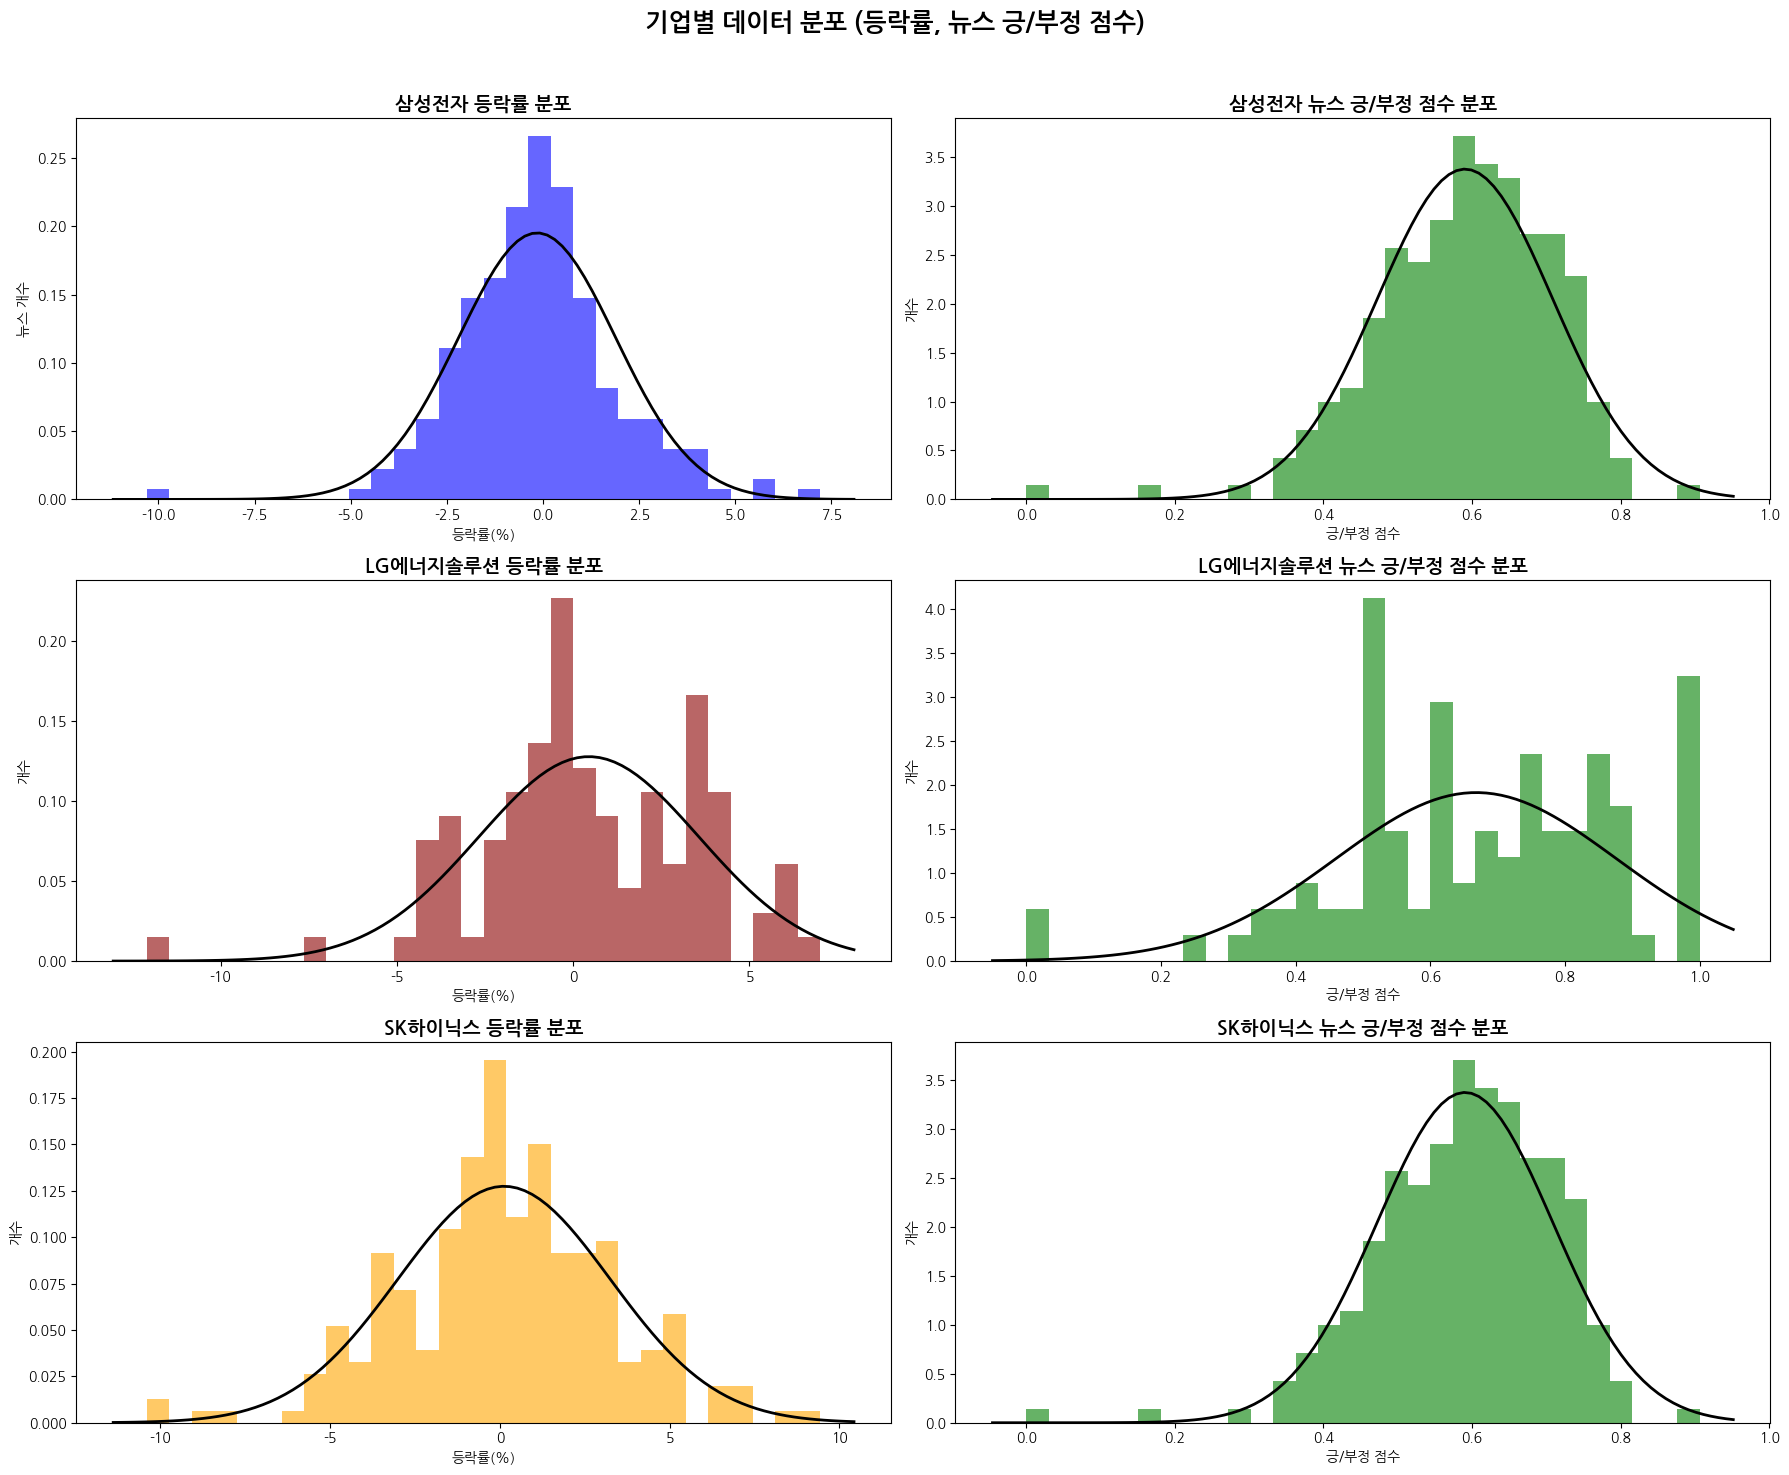

In [ ]:
# 정규 분포로 시각화
from scipy.stats import norm #정규 분포를 위한 모듈
import numpy as np

# 전체 figure 제작
fig, axes = plt.subplots(3, 2, figsize=(18, 15))
fig.suptitle("기업별 데이터 분포 (등락률, 뉴스 긍/부정 점수)", fontsize=18, fontweight='bold')

# 삼성전자 등락률
data = merged_samsung['등락률'].dropna()
mu, std = norm.fit(data)
axes[0, 0].hist(data, bins=30, density=True, alpha=0.6, color='blue')
xmin, xmax = axes[0, 0].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
axes[0, 0].plot(x, p, 'k', linewidth=2)
axes[0, 0].set_title("삼성전자 등락률 분포", fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel("등락률(%)")
axes[0, 0].set_ylabel("뉴스 개수")

# 삼성전자 뉴스 감정 점수
data = merged_samsung['긍/부정점수'].dropna()
mu, std = norm.fit(data)
axes[0, 1].hist(data, bins=30, density=True, alpha=0.6, color='green')
xmin, xmax = axes[0, 1].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
axes[0, 1].plot(x, p, 'k', linewidth=2)
axes[0, 1].set_title("삼성전자 뉴스 긍/부정 점수 분포", fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel("긍/부정 점수")
axes[0, 1].set_ylabel("개수")


# LG에너지솔루션 등락률 분포
data = merged_lg['등락률'].dropna()
mu, std = norm.fit(data)
axes[1, 0].hist(data, bins=30, density=True, alpha=0.6, color='darkred')
xmin, xmax = axes[1, 0].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
axes[1, 0].plot(x, p, 'k', linewidth=2)
axes[1, 0].set_title("LG에너지솔루션 등락률 분포", fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel("등락률(%)")
axes[1, 0].set_ylabel("개수")

# LG에너지솔루션 뉴스 감정 점수
data = merged_lg['긍/부정점수'].dropna()
mu, std = norm.fit(data)
axes[1, 1].hist(data, bins=30, density=True, alpha=0.6, color='green')
xmin, xmax = axes[1, 1].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
axes[1, 1].plot(x, p, 'k', linewidth=2)
axes[1, 1].set_title("LG에너지솔루션 뉴스 긍/부정 점수 분포", fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel("긍/부정 점수")
axes[1, 1].set_ylabel("개수")


# SK하이닉스 등락률 분포
data = merged_sk['등락률'].dropna()
mu, std = norm.fit(data)
axes[2, 0].hist(data, bins=30, density=True, alpha=0.6, color='orange')
xmin, xmax = axes[2, 0].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
axes[2, 0].plot(x, p, 'k', linewidth=2)
axes[2, 0].set_title("SK하이닉스 등락률 분포", fontsize=14, fontweight='bold')
axes[2, 0].set_xlabel("등락률(%)")
axes[2, 0].set_ylabel("개수")

# SK하이닉스 뉴스 감정 점수
data = merged_sk['긍/부정점수'].dropna()
mu, std = norm.fit(data)
axes[2, 1].hist(data, bins=30, density=True, alpha=0.6, color='green')
xmin, xmax = axes[2, 1].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
axes[2, 1].plot(x, p, 'k', linewidth=2)
axes[2, 1].set_title("SK하이닉스 뉴스 긍/부정 점수 분포", fontsize=14, fontweight='bold')
axes[2, 1].set_xlabel("긍/부정 점수")
axes[2, 1].set_ylabel("개수")


# 전체 시각화
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
# ----------------------------------------------------------
# 5. [추가 요청사항] ADF 검정 (Augmented Dickey-Fuller Test)
# ----------------------------------------------------------

def run_adf_test(series, title):
    """
    시계열 데이터에 대해 ADF 검정을 수행하고 결과를 출력하는 함수
    """
    print(f'\n======== [ {title} ] ADF Test ========')

    # 결측치(NaN)가 있으면 ADF 검정이 불가능하므로 제거
    series_clean = series.dropna()

    if len(series_clean) < 2:
        print("데이터 개수가 부족하여 검정을 수행할 수 없습니다.")
        return

    # autolag='AIC': 검정 통계량을 최적화하기 위해 자동으로 시차(lag)를 선택
    result = adfuller(series_clean.values, autolag='AIC')

    print(f'ADF Statistic: {result[0]:.6f}')
    print(f'p-value: {result[1]:.6f}')
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value:.4f}')

    # 결과 해석 출력
    if result[1] < 0.05:
        print(">> 결과 해석: p-value가 0.05보다 작으므로 '정상 시계열(Stationary)'입니다. (귀무가설 기각)")
    else:
        print(">> 결과 해석: p-value가 0.05보다 크므로 '비정상 시계열(Non-Stationary)'일 가능성이 높습니다. (귀무가설 채택)")

# 각 기업별 '등락률'에 대해 ADF 검정 수행
print("\n >>>>>> 기업별 주가 등락률 ADF 검정 결과 <<<<<<")
run_adf_test(stock_samsung["등락률"], "삼성전자 등락률")
run_adf_test(stock_lg["등락률"], "LG에너지솔루션 등락률")
run_adf_test(stock_sk["등락률"], "SK하이닉스 등락률")

# (필요시) 뉴스 점수에 대해서도 수행 가능
# run_adf_test(daily_sentiment_samsung["긍/부정점수"], "삼성전자 뉴스 심리지수")